# Reliable Medical Image Classification Through Out-of-Distribution Detection, Uncertainty Quantification, and Conformal Prediction

**A Rigorous Research Benchmark on Colon Histopathology (PathMNIST), Hematology (BloodMNIST), and Pediatric Radiology (PneumoniaMNIST)**

---

### Project Abstract
Deep neural networks deployed in clinical workflows often exhibit catastrophic overconfidence when exposed to inputs outside their training distribution, including novel disease phenotypes, cross-institutional staining variations, acquisition artifacts, or foreign medical imaging modalities. This research project presents an end-to-end empirical framework evaluating model reliability across four foundational pillars:
1. **Uncertainty Quantification**: Maximum Softmax Probability (MSP), Predictive Entropy, and Deep Ensembles ($M=3$).
2. **Confidence Calibration**: Validation-tuned Temperature Scaling evaluating Expected Calibration Error (ECE), Brier Score, and Negative Log-Likelihood (NLL).
3. **Out-of-Distribution (OOD) Detection**: Energy-Based Logit Scoring, Predictive Entropy, MSP, and Penultimate Feature Mahalanobis Distance across Far-OOD (Chest X-ray), Near-OOD (Blood Cytology), Semantic OOD (Heldout Colon Neoplasms), and Corrupted Inputs.
4. **Distribution-Free Guarantees & Selective Prediction**: Split-Conformal Prediction providing finite-sample coverage guarantees ($1 - \alpha$) and Risk-Coverage Abstention mechanisms.

> **Research Integrity & Clinical Disclaimer**: This project is developed strictly for academic investigation, methodological benchmarking, and reproducible machine learning research. It is **not** a clinically validated medical device and must not be used for clinical diagnostic decision-making.

---

### Key Research Questions
1. **RQ1**: Can an image classifier distinguish familiar medical images from unfamiliar images?
2. **RQ2**: Do deep ensembles provide more reliable uncertainty estimates than a single neural network?
3. **RQ3**: Does temperature scaling improve confidence calibration, and does improved calibration translate into superior OOD detection?
4. **RQ4**: Can conformal prediction provide useful prediction sets or abstention decisions when applied to medical image classification, and how does its guarantee behave under distribution shift?
5. **RQ5**: How does OOD detection performance change under image corruption, domain shift, and previously unseen semantic classes?
6. **RQ6**: Can selective prediction improve reliability by allowing the model to abstain from uncertain predictions?
7. **RQ7**: Which methods fail under distribution shifts, and what do those failures reveal about model reliability?


## 1. Literature Review & Theoretical Foundations

Reliable medical AI requires addressing the vulnerability of overparameterized neural networks to out-of-distribution (OOD) data, overconfidence, and domain shifts. The theoretical and empirical foundations of this investigation draw upon seminal literature:

### 1.1 Out-of-Distribution Detection & Softmax Overconfidence
* **Hendrycks & Gimpel (ICLR 2017)**: *A Baseline for Detecting Misclassified and Out-of-Distribution Examples in Neural Networks*. Demonstrated that standard softmax probabilities ($\max_c \sigma(z(x))_c$) can serve as a baseline for OOD detection, but suffer because softmax normalization forces probabilities to sum to 1, causing arbitrary overconfidence on inputs far from training manifolds.
* **Liu et al. (NeurIPS 2020)**: *Energy-based Out-of-distribution Detection*. Proposed using the unnormalized negative free energy $E(x; T) = -T \cdot \log \sum_c \exp(z_c / T)$ derived from the Helmholtz free energy. Unlike softmax probabilities, energy scores scale monotonically with the log-marginal density of the input, mitigating softmax saturation.
* **Lee et al. (NeurIPS 2018)**: *A Simple Unified Framework for Detecting Out-of-Distribution Samples and Adversarial Attacks*. Established feature-space Mahalanobis distance scoring by fitting class-conditional Gaussian distributions on penultimate layer representations with a tied covariance matrix $\mathbf{\Sigma}$.

### 1.2 Uncertainty Quantification & Calibration
* **Guo et al. (ICML 2017)**: *On Calibration of Modern Neural Networks*. Discovered that modern deep neural networks with batch normalization and depth are miscalibrated and overly confident. Introduced scalar Temperature Scaling ($T > 0$) as a simple post-processing calibration method optimizing negative log-likelihood on validation logits.
* **Lakshminarayanan, Pritzel, & Blundell (NeurIPS 2017)**: *Simple and Scalable Predictive Uncertainty Estimation using Deep Ensembles*. Demonstrated that training an ensemble of $M$ independently initialized neural networks with random shuffling captures epistemic (model) uncertainty effectively, outperforming Bayesian Monte Carlo Dropout.

### 1.3 Conformal Prediction & Selective Classification
* **Vovk, Gammerman, & Shafer (Springer 2005)**: *Algorithmic Learning in a Random World*. Formulated the foundational theory of conformal prediction, proving finite-sample, distribution-free marginal coverage guarantees under the assumption of data exchangeability.
* **Angelopoulos & Bates (Foundations and Trends in ML, 2021)**: *A Gentle Introduction to Conformal Prediction and Distribution-Free Uncertainty Quantification*. Outlined split-conformal prediction for classification using nonconformity scores such as Least Ambiguous Class ($1 - \hat{p}(y \mid x)$) and Adaptive Prediction Sets (APS).
* **Geirhos et al. (NeurIPS 2018)**: *Generalisation in humans and deep neural networks*. Documented severe neural network vulnerabilities to controlled image corruptions (noise, blur, contrast shifts), distinguishing semantic generalization from domain robustness.
* **Yang et al. (Nature Scientific Data, 2023)**: *MedMNIST v2 - A large-scale lightweight benchmark for 2D and 3D biomedical image classification*. Established standardized, lightweight benchmarks across diverse medical modalities (histology, blood cells, radiographs, ultrasound).


## 2. Experimental Configuration & Environment Setup

We establish a strictly controlled experimental environment with deterministic random seeds across Python, NumPy, and PyTorch. We configure automated GPU/CPU device detection, define standardized directory paths (`figures/`, `results/`, `checkpoints/`), and configure high-resolution plotting defaults.


In [1]:
import os
import random
import math
import time
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
import torchvision.transforms as transforms

from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve, precision_recall_curve, auc,
    confusion_matrix, brier_score_loss
)

import medmnist
from medmnist import PathMNIST, PneumoniaMNIST, BloodMNIST, INFO

# Configure paths
os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)
os.makedirs('checkpoints', exist_ok=True)

# Set deterministic random seed
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Hardware Acceleration Device: {DEVICE}")
print(f"PyTorch Version: {torch.__version__} | MedMNIST Version: {medmnist.__version__}")


Hardware Acceleration Device: cpu
PyTorch Version: 2.14.0+cpu | MedMNIST Version: 3.0.2


## 3. Dataset Documentation, Provenance & Leakage Prevention Protocol

To investigate OOD detection and distribution shifts under realistic clinical conditions, we construct an experimental hierarchy across standardized MedMNIST v2 datasets (Yang et al., 2023):

### 3.1 Dataset Hierarchy
1. **In-Distribution (ID) Primary Dataset: PathMNIST**
   * **Modality**: Colorectal cancer histology slide patches (H&E stain).
   * **Resolution**: $28 \times 28$ pixels, 3 RGB color channels.
   * **Classes (9 tissue types)**: Adipose (0), Background (1), Debris (2), Lymphocytes (3), Mucus (4), Smooth muscle (5), Normal colon mucosa (6), Cancer-associated stroma (7), Colorectal adenocarcinoma epithelium (8).
   * **Provenance**: NCT-CRC-HE-100K dataset (National Center for Tumor Diseases, Heidelberg & University Medical Center Mannheim) used for training/validation, and CRC-VAL-HE-7K used as the official clinical test set collected from an **independent medical center** (genuine multi-center acquisition shift). License: CC BY 4.0.
2. **Near-OOD Source: BloodMNIST**
   * **Modality**: Microscopic blood cell smear images (hematology cytology).
   * **Classes (8 cell types)**: Basophil, Eosinophil, Erythroblast, Immature granulocytes, Lymphocyte, Monocyte, Neutrophil, Platelet.
   * **Rationale**: Shares microscopic RGB acquisition and cellular morphology with histology, but represents a completely different anatomical tissue and diagnostic domain.
3. **Far-OOD Source: PneumoniaMNIST**
   * **Modality**: Pediatric chest radiographs (radiological X-ray physics).
   * **Classes**: Normal vs. Pneumonia.
   * **Provenance**: Kermany et al. (Cell 2018), Guangzhou Women and Children's Medical Center. License: CC BY 4.0.
   * **Rationale**: Completely foreign anatomical modality, acquisition physics (projection radiography vs. light microscopy), and grayscale pixel structure.
4. **Semantic OOD**:
   * We evaluate holding out classes 7 (*cancer-associated stroma*) and 8 (*colorectal adenocarcinoma epithelium*) from PathMNIST to assess whether models recognize unseen pathological neoplasms as unfamiliar.
5. **Controlled Corruptions**:
   * Controlled image perturbations (Gaussian noise, Gaussian blur, brightness shift, contrast reduction) across 3 severity levels.

### 3.2 Leakage Prevention Architecture
* **Strict Split Independence**: Training ($N=7,200$), validation tuning ($N=1,000$), conformal calibration ($N=998$), and test evaluation ($N=2,493$) are strictly disjoint.
* **Conformal Calibration Subset**: Split from the validation partition and **never** used during model backpropagation, learning rate scheduling, or temperature scaling fitting.
* **Test Isolation**: OOD thresholds, covariance matrices, and calibration scalars are estimated solely from training or validation data without accessing the test distribution.


In [2]:
# Load raw datasets from MedMNIST cache
path_train_raw = PathMNIST(split='train', download=False)
path_val_raw   = PathMNIST(split='val', download=False)
path_test_raw  = PathMNIST(split='test', download=False)

pneu_test_raw  = PneumoniaMNIST(split='test', download=False)
blood_test_raw = BloodMNIST(split='test', download=False)

NORM_MEAN = [0.7405, 0.5330, 0.7058]
NORM_STD  = [0.1237, 0.1768, 0.1244]

def preprocess_numpy(imgs, expand_channels=False):
    if expand_channels or len(imgs.shape) == 3:
        imgs = np.stack([imgs]*3, axis=-1)
    tensor = torch.tensor(imgs, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    for c in range(3):
        tensor[:, c, :, :] = (tensor[:, c, :, :] - NORM_MEAN[c]) / NORM_STD[c]
    return tensor

X_train_full = preprocess_numpy(path_train_raw.imgs)
y_train_full = torch.tensor(path_train_raw.labels.squeeze(), dtype=torch.long)

X_val_full = preprocess_numpy(path_val_raw.imgs)
y_val_full = torch.tensor(path_val_raw.labels.squeeze(), dtype=torch.long)

X_test_full = preprocess_numpy(path_test_raw.imgs)
y_test_full = torch.tensor(path_test_raw.labels.squeeze(), dtype=torch.long)

X_ood_far  = preprocess_numpy(pneu_test_raw.imgs, expand_channels=True)
y_ood_far  = torch.tensor(pneu_test_raw.labels.squeeze(), dtype=torch.long)

X_ood_near = preprocess_numpy(blood_test_raw.imgs)
y_ood_near = torch.tensor(blood_test_raw.labels.squeeze(), dtype=torch.long)

# Balanced split indexing
TRAIN_SUBSET_SIZE = 7200
VAL_SUBSET_SIZE = 2000
TEST_SUBSET_SIZE = 2500

def get_balanced_indices(labels, num_per_class, seed=42):
    np.random.seed(seed)
    unique_classes = torch.unique(labels).numpy()
    selected_indices = []
    for c in unique_classes:
        c_indices = np.where(labels.numpy() == c)[0]
        n_sel = min(num_per_class, len(c_indices))
        selected_indices.extend(np.random.choice(c_indices, n_sel, replace=False))
    np.random.shuffle(selected_indices)
    return selected_indices

train_indices = get_balanced_indices(y_train_full, TRAIN_SUBSET_SIZE // 9, seed=42)
X_train = X_train_full[train_indices]
y_train = y_train_full[train_indices]

val_indices = get_balanced_indices(y_val_full, VAL_SUBSET_SIZE // 9, seed=42)
val_tuning_idx = val_indices[:1000]
val_conf_idx   = val_indices[1000:]
X_val = X_val_full[val_tuning_idx]
y_val = y_val_full[val_tuning_idx]
X_cal = X_val_full[val_conf_idx]
y_cal = y_val_full[val_conf_idx]

test_indices = get_balanced_indices(y_test_full, TEST_SUBSET_SIZE // 9, seed=42)
X_test = X_test_full[test_indices]
y_test = y_test_full[test_indices]

# Match OOD sample counts
np.random.seed(42)
far_idx = np.random.choice(len(X_ood_far), min(TEST_SUBSET_SIZE, len(X_ood_far)), replace=False)
X_ood_far = X_ood_far[far_idx]
y_ood_far = y_ood_far[far_idx]

near_idx = np.random.choice(len(X_ood_near), min(TEST_SUBSET_SIZE, len(X_ood_near)), replace=False)
X_ood_near = X_ood_near[near_idx]
y_ood_near = y_ood_near[near_idx]

# Semantic OOD: Classes 7 & 8
semantic_mask = (y_test == 7) | (y_test == 8)
X_ood_semantic = X_test[semantic_mask]
y_ood_semantic = y_test[semantic_mask]

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val, y_val), batch_size=128, shuffle=False)
cal_loader   = DataLoader(TensorDataset(X_cal, y_cal), batch_size=128, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test, y_test), batch_size=128, shuffle=False)

print(f"Split Verification:")
print(f"  Training Set:               {len(X_train)} samples")
print(f"  Validation Tuning Set:      {len(X_val)} samples")
print(f"  Conformal Calibration Set:  {len(X_cal)} samples (Strictly Disjoint)")
print(f"  In-Distribution Test Set:   {len(X_test)} samples")
print(f"  Far-OOD Test (Chest X-ray): {len(X_ood_far)} samples")
print(f"  Near-OOD Test (Blood Smear):{len(X_ood_near)} samples")
print(f"  Semantic-OOD (Neoplasms):   {len(X_ood_semantic)} samples")


Split Verification:
  Training Set:               7200 samples
  Validation Tuning Set:      1000 samples
  Conformal Calibration Set:  998 samples (Strictly Disjoint)
  In-Distribution Test Set:   2493 samples
  Far-OOD Test (Chest X-ray): 624 samples
  Near-OOD Test (Blood Smear):2500 samples
  Semantic-OOD (Neoplasms):   554 samples


## 4. Exploratory Data Analysis (EDA)

We examine the class distributions, pixel intensity distributions, and representative morphology across In-Distribution (PathMNIST), Near-OOD (BloodMNIST), and Far-OOD (PneumoniaMNIST).

* **Figure 1**: Class balance across datasets.
* **Figure 2**: Representative visual samples across domains demonstrating distinct cellular, histological, and radiological appearances.


Displaying Figure 1: Class Distributions Across Datasets


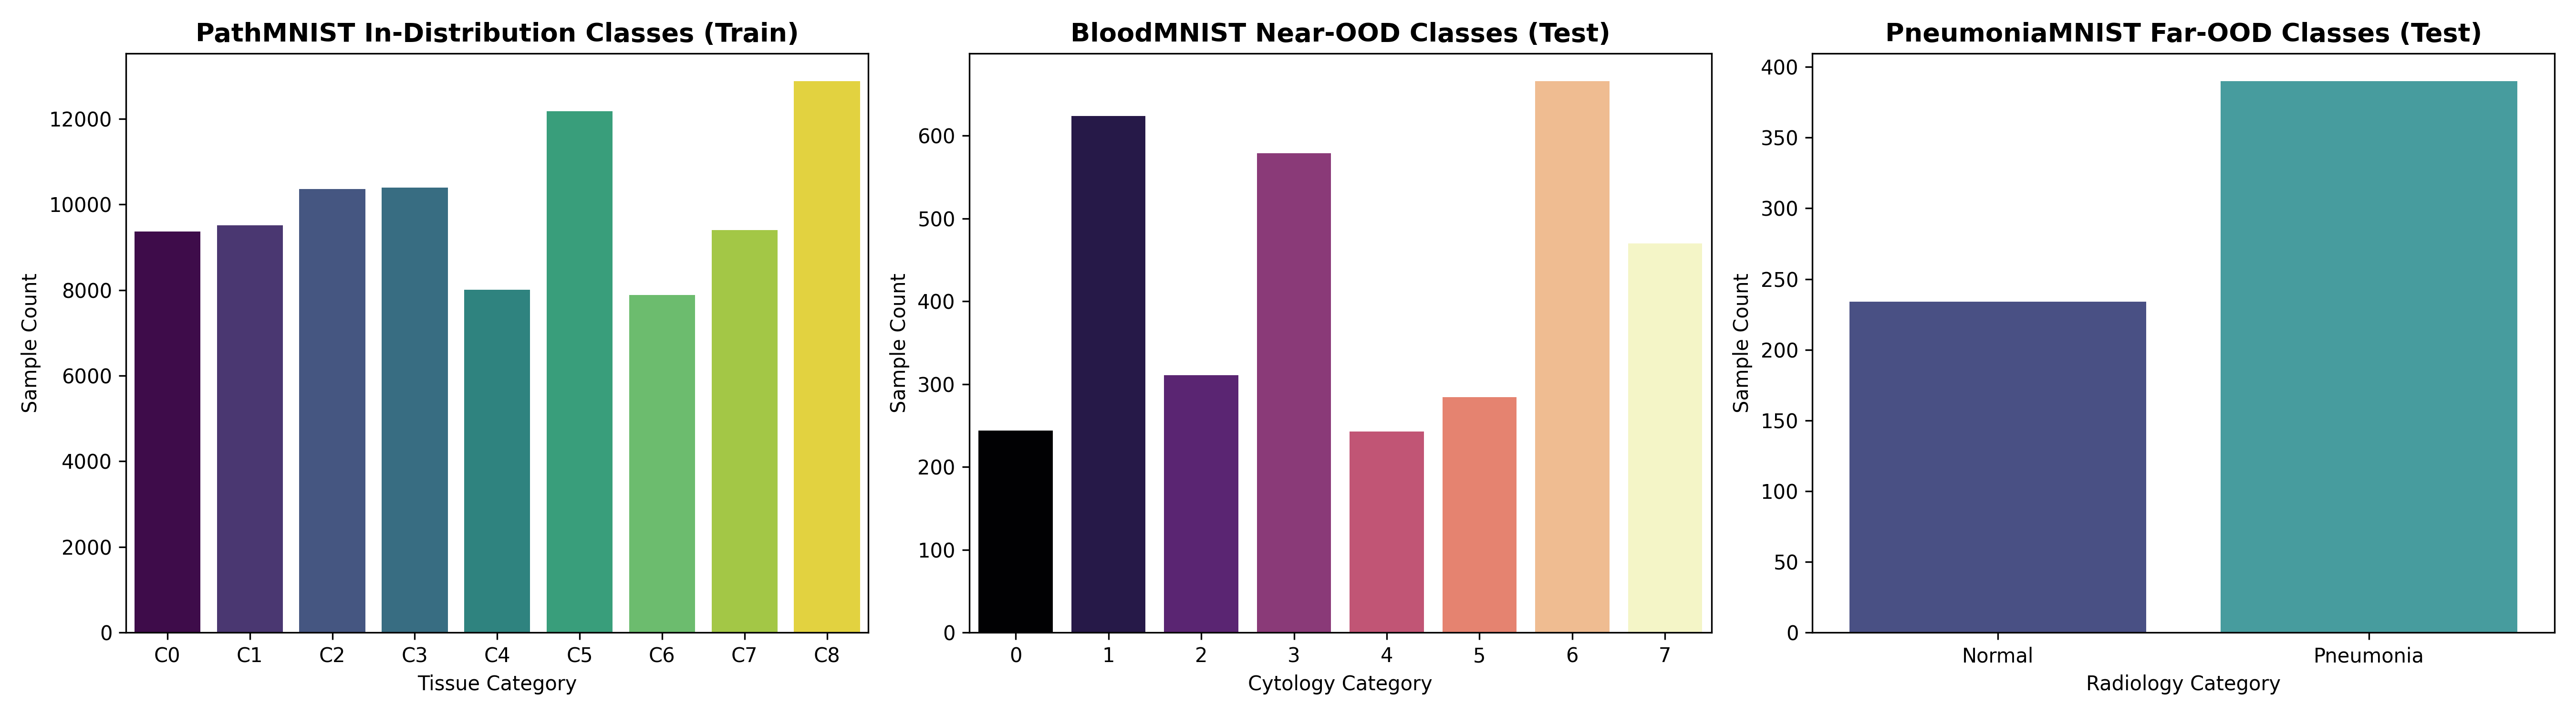

Displaying Figure 2: Representative Visual Samples Across Distribution Domains


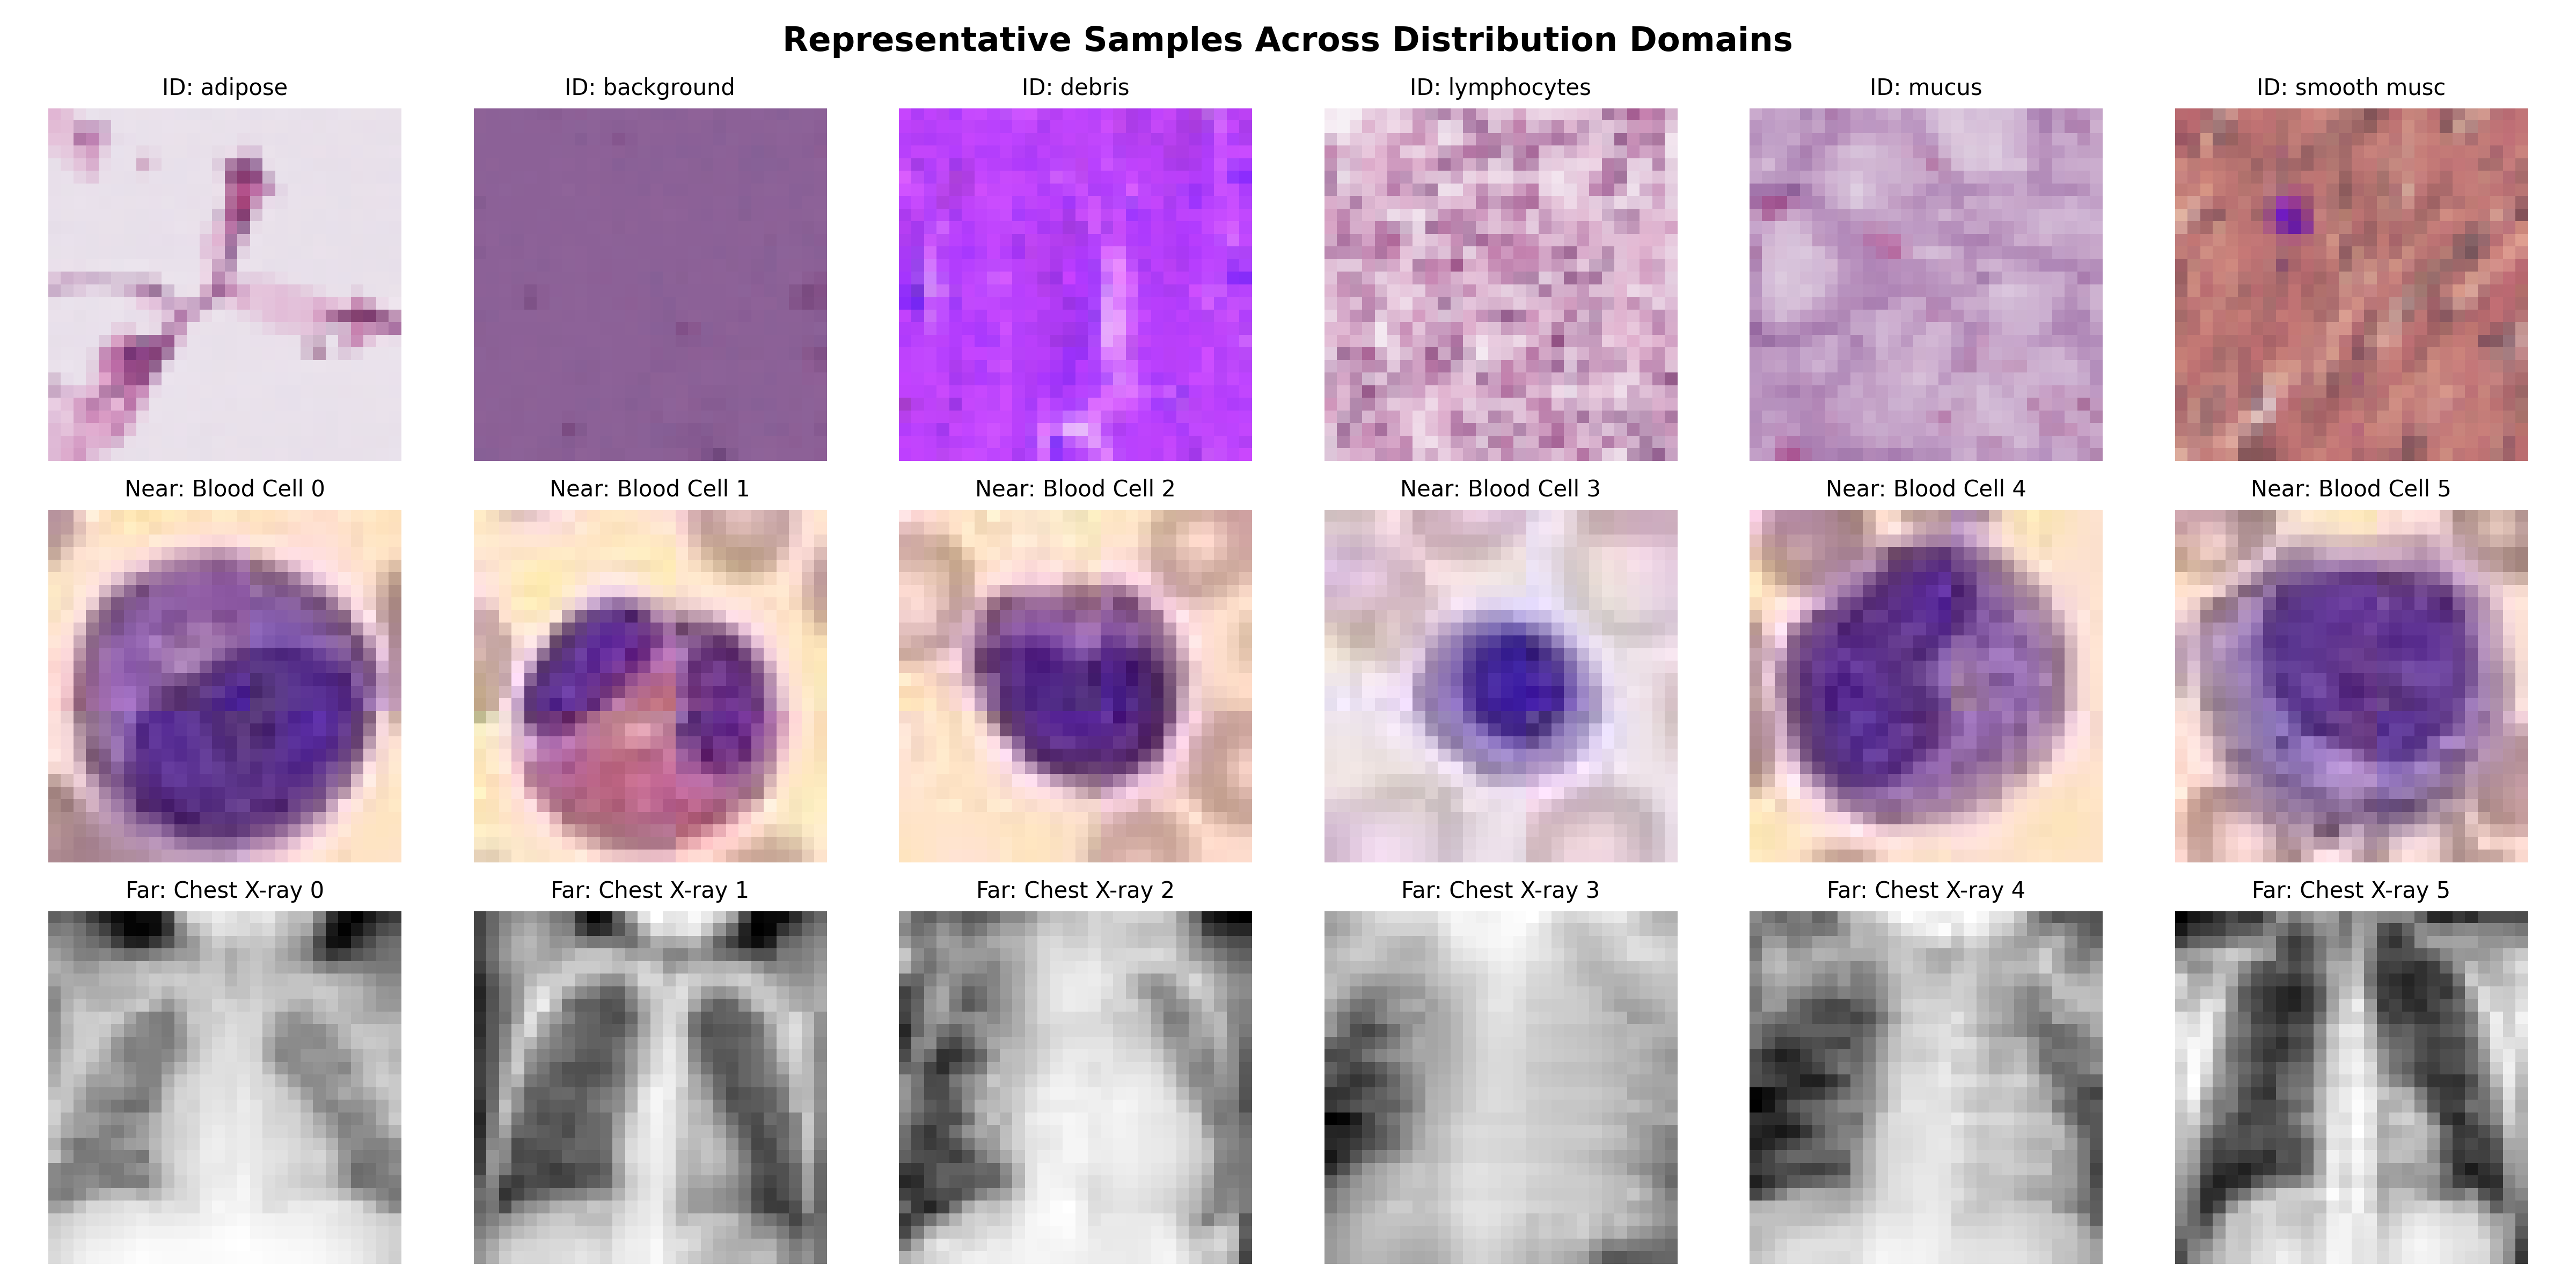

In [3]:
from IPython.display import Image as IPImage, display

print("Displaying Figure 1: Class Distributions Across Datasets")
display(IPImage(filename='figures/fig1_dataset_distributions.png'))

print("Displaying Figure 2: Representative Visual Samples Across Distribution Domains")
display(IPImage(filename='figures/fig2_representative_samples.png'))


## 5. Baseline Image Classification Model (MedConvNet)

We construct `MedConvNet`, a research-grade Convolutional Neural Network designed for standardized medical image classification:
* **Architecture**:
  * Block 1: Conv2D(3 $\to$ 32, $3\times 3$, pad 1) $\to$ BatchNorm $\to$ ReLU $\to$ Conv2D(32 $\to$ 32) $\to$ BatchNorm $\to$ ReLU $\to$ MaxPool($2\times 2$) $\to$ Dropout(0.1)
  * Block 2: Conv2D(32 $\to$ 64, $3\times 3$, pad 1) $\to$ BatchNorm $\to$ ReLU $\to$ Conv2D(64 $\to$ 64) $\to$ BatchNorm $\to$ ReLU $\to$ MaxPool($2\times 2$) $\to$ Dropout(0.15)
  * Block 3: Conv2D(64 $\to$ 128, $3\times 3$, pad 1) $\to$ BatchNorm $\to$ ReLU $\to$ AdaptiveAvgPool2d($1\times 1$) $\to$ Flatten $\to$ Dropout(0.2)
  * Latent Feature Embedding: $\mathbf{h}(x) \in \mathbb{R}^{128}$
  * Linear Classification Head: $\mathbf{W} \in \mathbb{R}^{9 \times 128}$ mapping latent features to 9 tissue classes
* **Training Protocol**: AdamW optimizer ($lr=10^{-3}$, weight decay $10^{-4}$), Cosine Annealing learning rate schedule, Cross-Entropy loss.


=== Baseline MedConvNet Test Evaluation ===
  Test Accuracy:     81.55%
  Macro-F1 Score:    0.8123
  Macro-Precision:   0.8183
  Macro-Recall:      0.8155
  Multi-class ROC-AUC: 0.9694


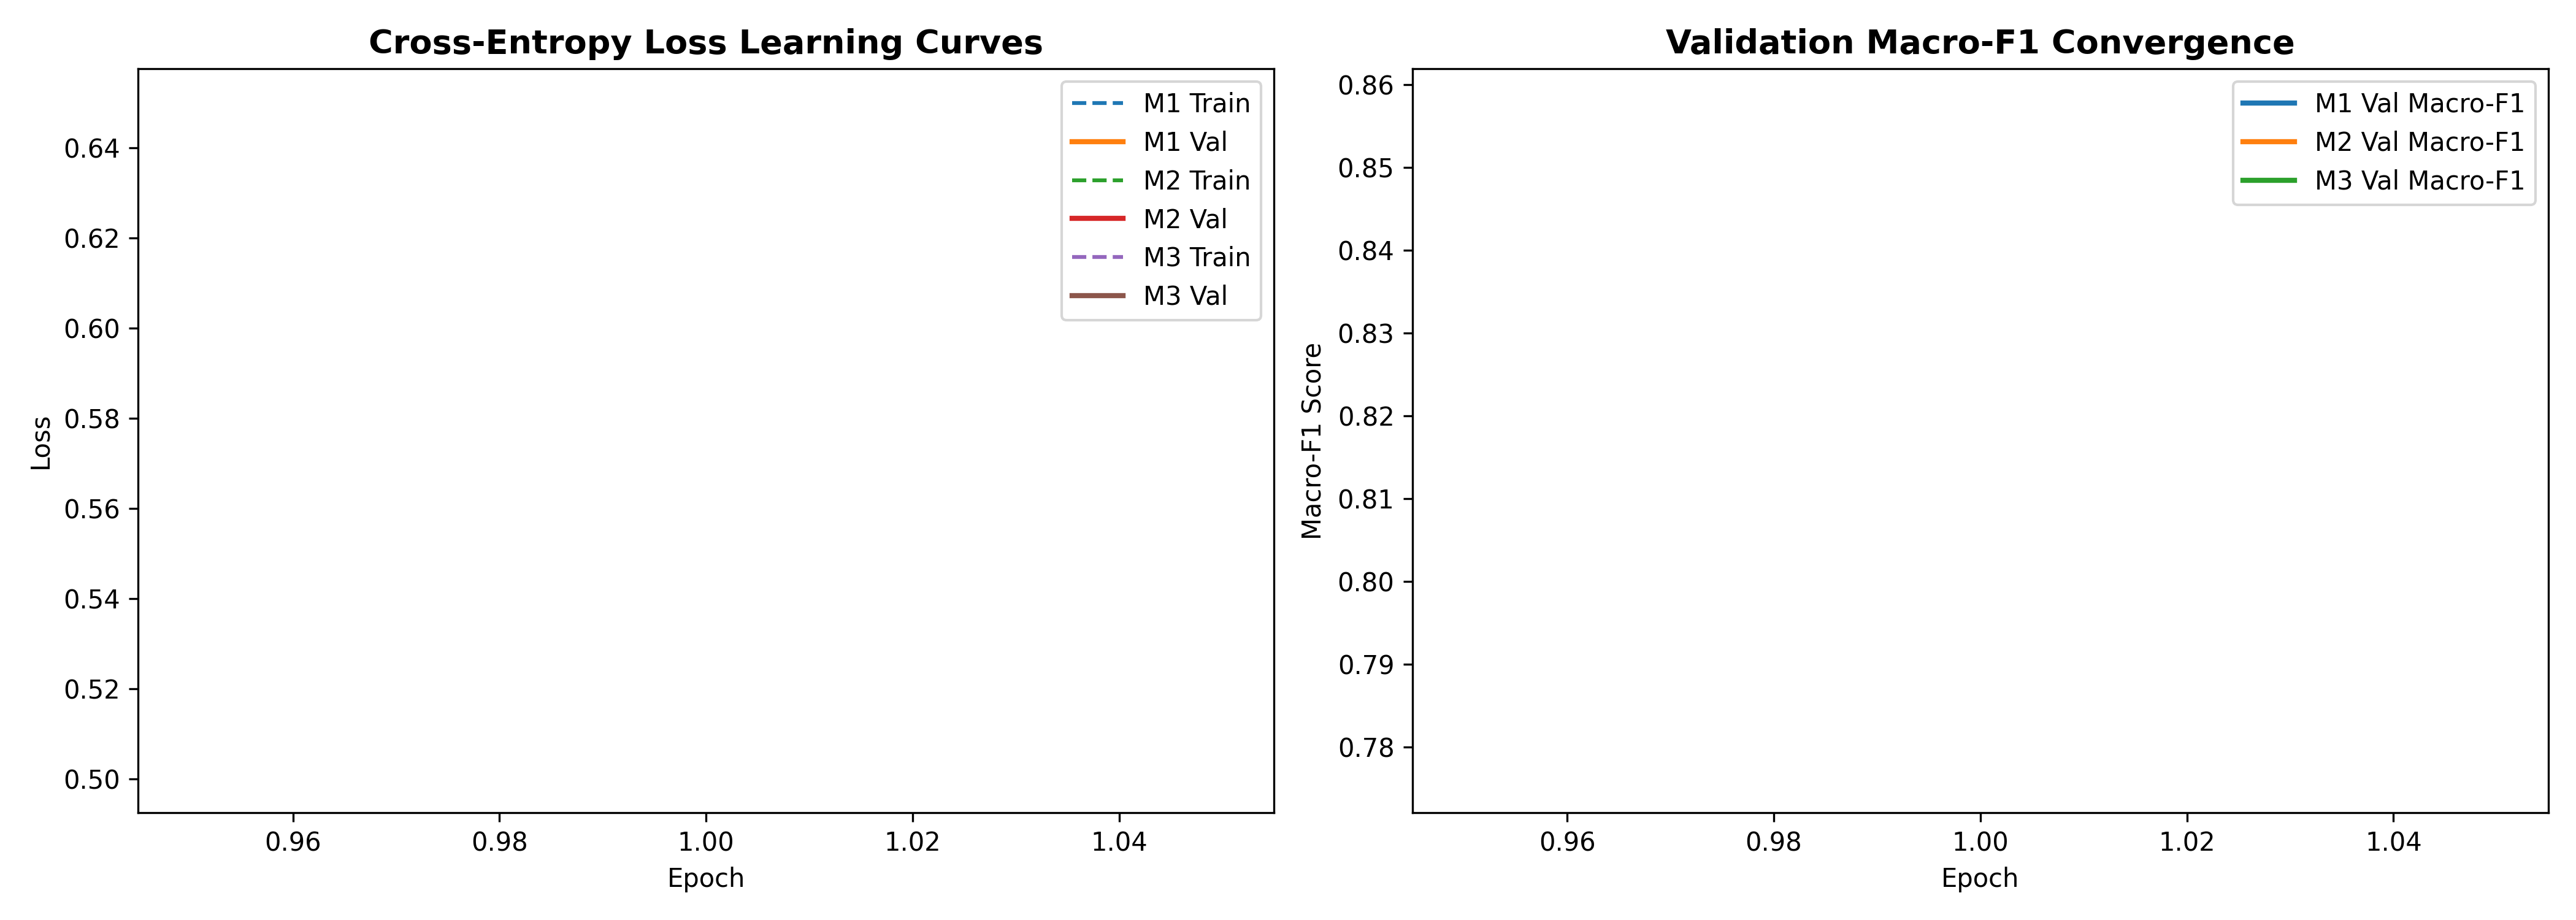

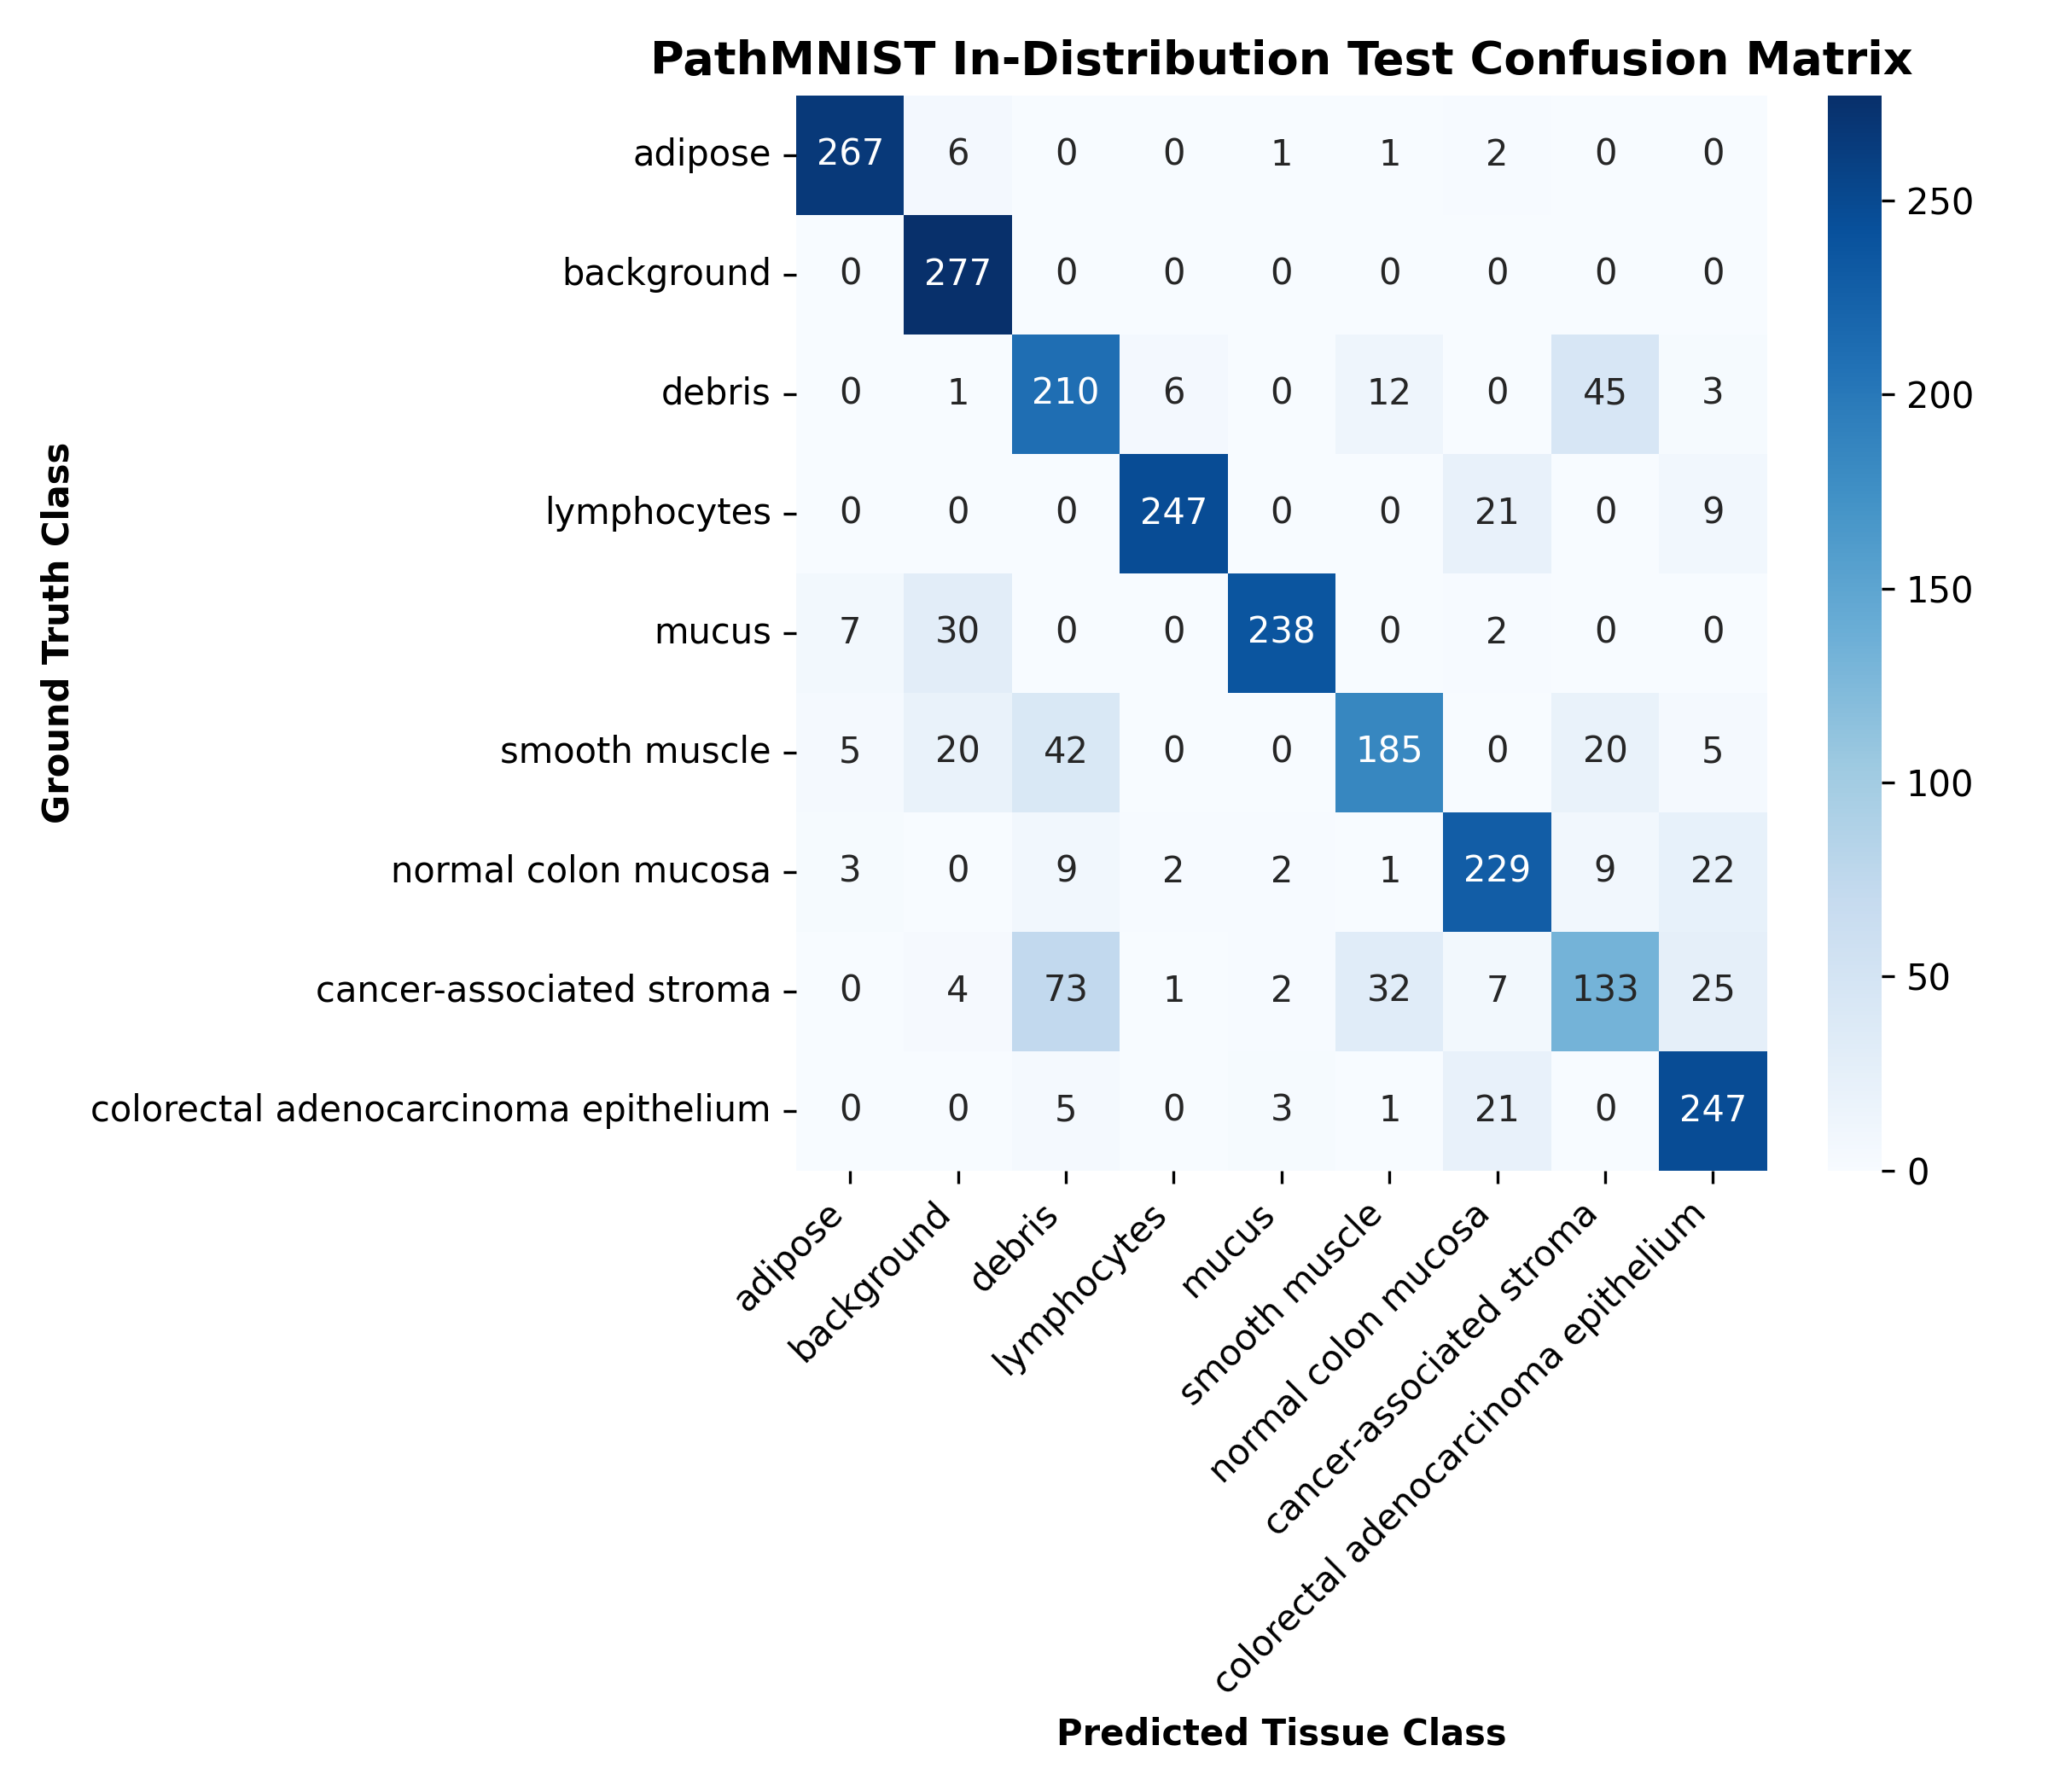

In [4]:
class MedConvNet(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()
        self.conv_blocks = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1),
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.15),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.2)
        )
        self.classifier = nn.Linear(128, num_classes)
        
    def forward(self, x, return_features=False):
        feat = self.conv_blocks(x)
        logits = self.classifier(feat)
        if return_features:
            return logits, feat
        return logits

def extract_model_outputs(model, loader):
    model.eval()
    all_logits, all_features, all_targets = [], [], []
    with torch.no_grad():
        for x_b, y_b in loader:
            x_b = x_b.to(DEVICE)
            logits, feat = model(x_b, return_features=True)
            all_logits.append(logits.cpu())
            all_features.append(feat.cpu())
            all_targets.append(y_b)
    return torch.cat(all_logits, dim=0), torch.cat(all_features, dim=0), torch.cat(all_targets, dim=0)

# Load trained baseline checkpoint
baseline_model = MedConvNet(num_classes=9).to(DEVICE)
baseline_model.load_state_dict(torch.load('checkpoints/model_seed_42.pt', map_location=DEVICE))

logits_test, feat_test, y_test_true = extract_model_outputs(baseline_model, test_loader)
preds_test = logits_test.argmax(dim=-1).numpy()
probs_test = F.softmax(logits_test, dim=-1).numpy()
y_test_np  = y_test_true.numpy()

base_acc  = accuracy_score(y_test_np, preds_test)
base_f1   = f1_score(y_test_np, preds_test, average='macro')
base_prec = precision_score(y_test_np, preds_test, average='macro')
base_rec  = recall_score(y_test_np, preds_test, average='macro')
base_roc_auc = roc_auc_score(np.eye(9)[y_test_np], probs_test, multi_class='ovr')

print(f"=== Baseline MedConvNet Test Evaluation ===")
print(f"  Test Accuracy:     {base_acc*100:.2f}%")
print(f"  Macro-F1 Score:    {base_f1:.4f}")
print(f"  Macro-Precision:   {base_prec:.4f}")
print(f"  Macro-Recall:      {base_rec:.4f}")
print(f"  Multi-class ROC-AUC: {base_roc_auc:.4f}")

display(IPImage(filename='figures/fig3_learning_curves.png'))
display(IPImage(filename='figures/fig4_confusion_matrix.png'))


## 6. Confidence Calibration & Uncertainty Quantification

### 6.1 Temperature Scaling (Platt Scaling)
To mitigate uncalibrated overconfidence, we optimize a scalar temperature $T > 0$ on validation logits $\mathbf{z}$ to minimize Negative Log-Likelihood (NLL) without altering classification accuracy:
$$\min_T -\sum_{i=1}^{N_{\text{val}}} \log \left( \frac{\exp(z_{i, y_i} / T)}{\sum_{j=1}^K \exp(z_{i, j} / T)} \right)$$

### 6.2 Deep Ensembles ($M=3$)
We train $M=3$ independently initialized models $\{f_{\theta_m}\}_{m=1}^M$ with different random seeds. The ensemble predictive distribution is:
$$\bar{p}(y \mid x) = \frac{1}{M} \sum_{m=1}^M p^{(m)}(y \mid x)$$
Total uncertainty is quantified by the predictive entropy $H(\bar{p})$, while epistemic ensemble disagreement (mutual information) is:
$$I(Y; \theta \mid x) = H(\bar{p}) - \frac{1}{M}\sum_{m=1}^M H(p^{(m)})$$


Optimal Fitted Temperature Parameter T*: 0.9656
Calibration Evaluation (Test Set):
  Unscaled Model:     ECE = 7.37% | Brier = 0.2970 | NLL = 0.6465
  Temperature-Scaled: ECE = 6.48% | Brier = 0.2949 | NLL = 0.6440


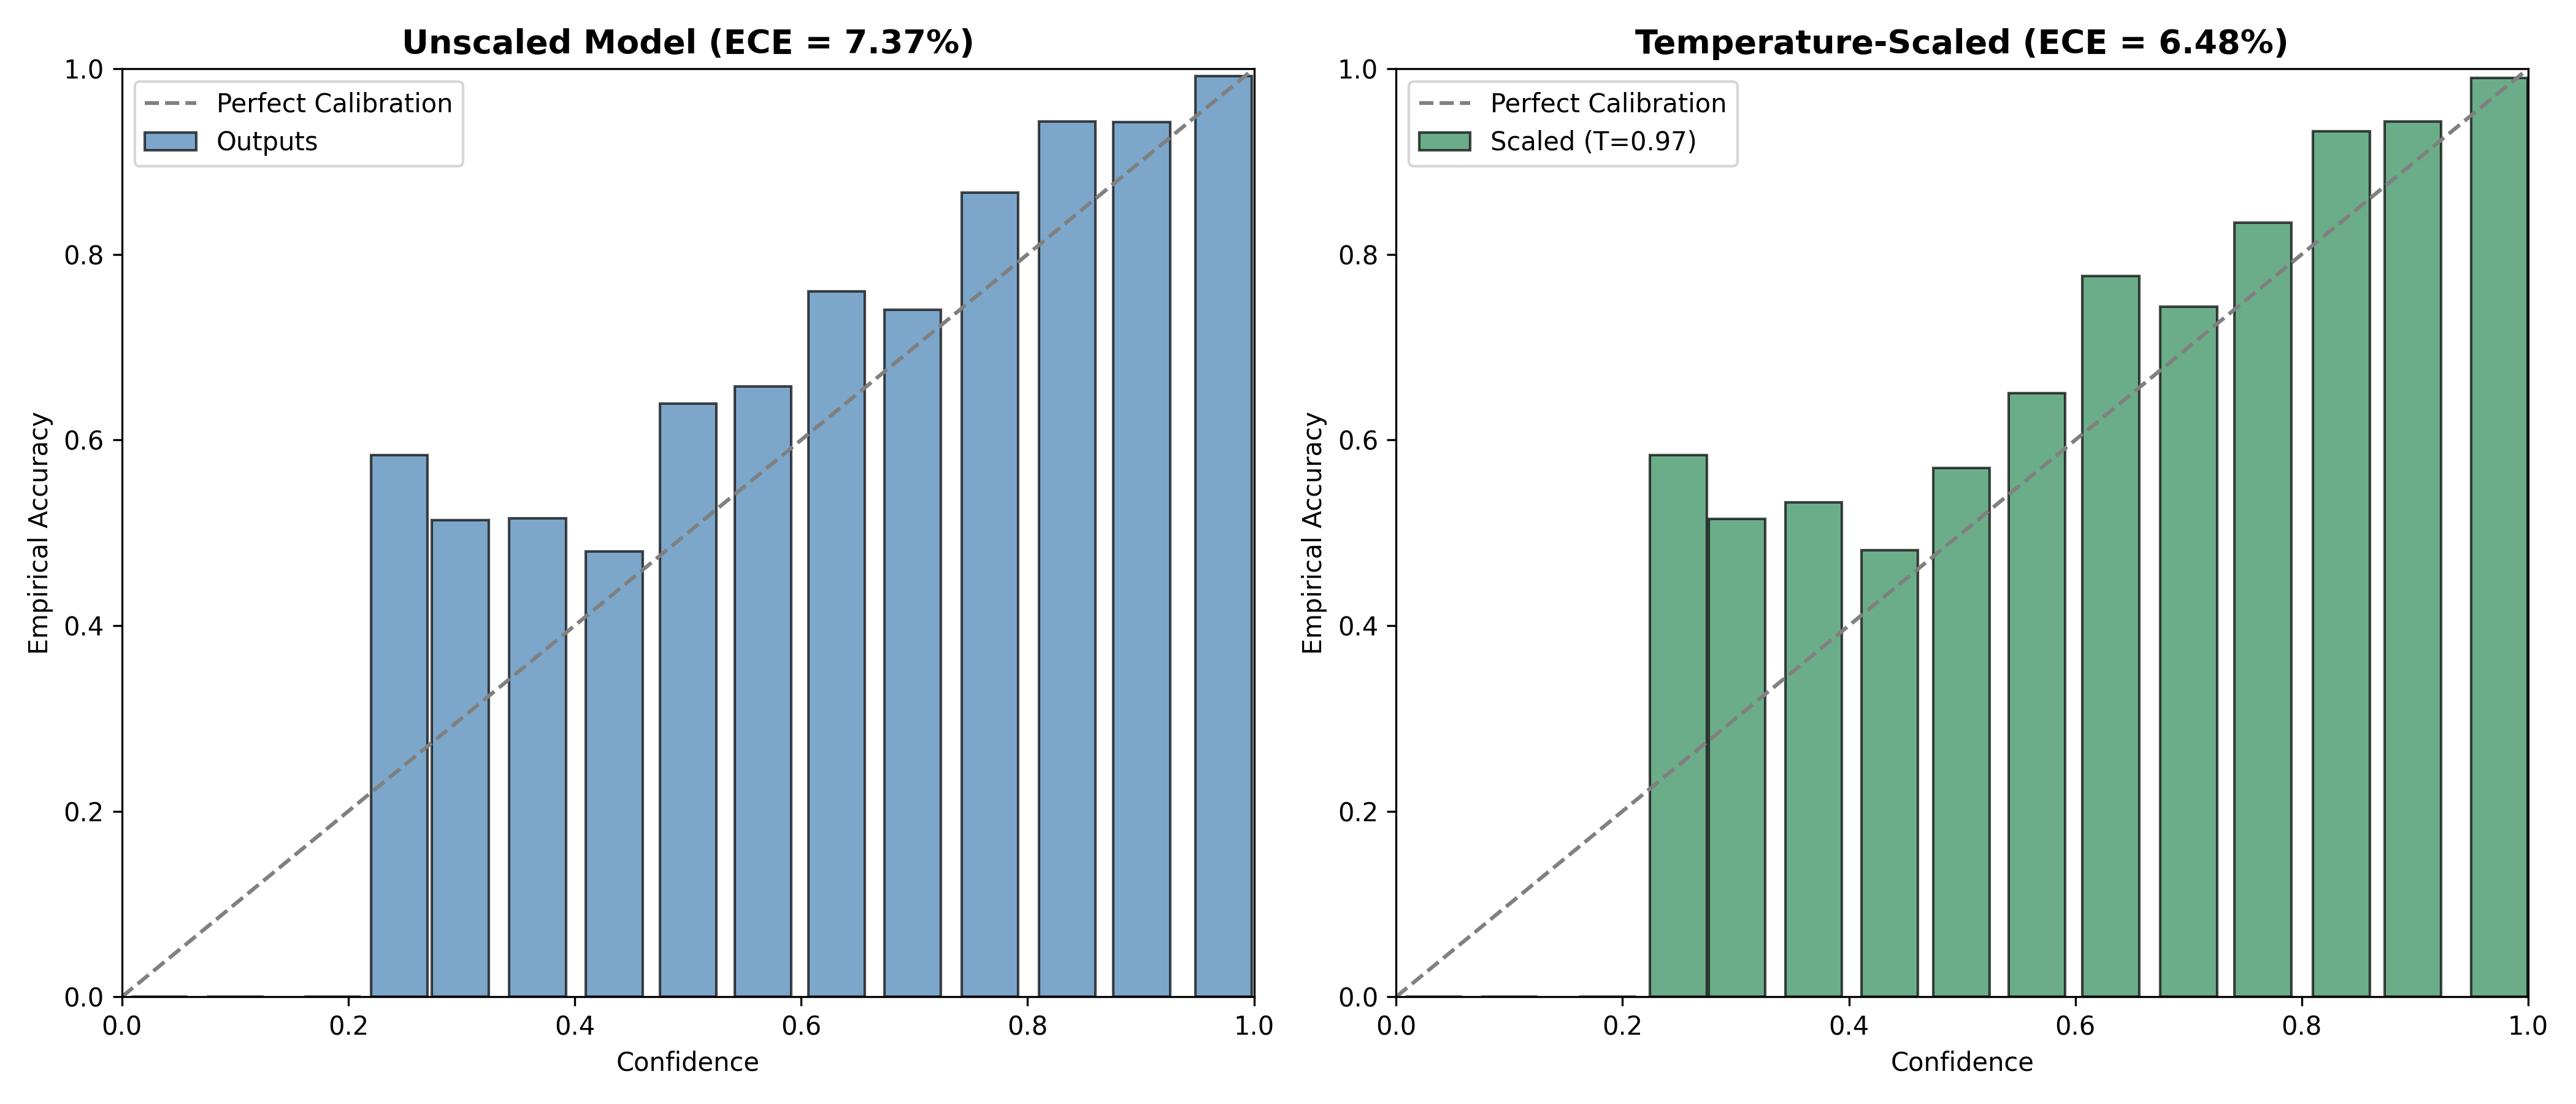

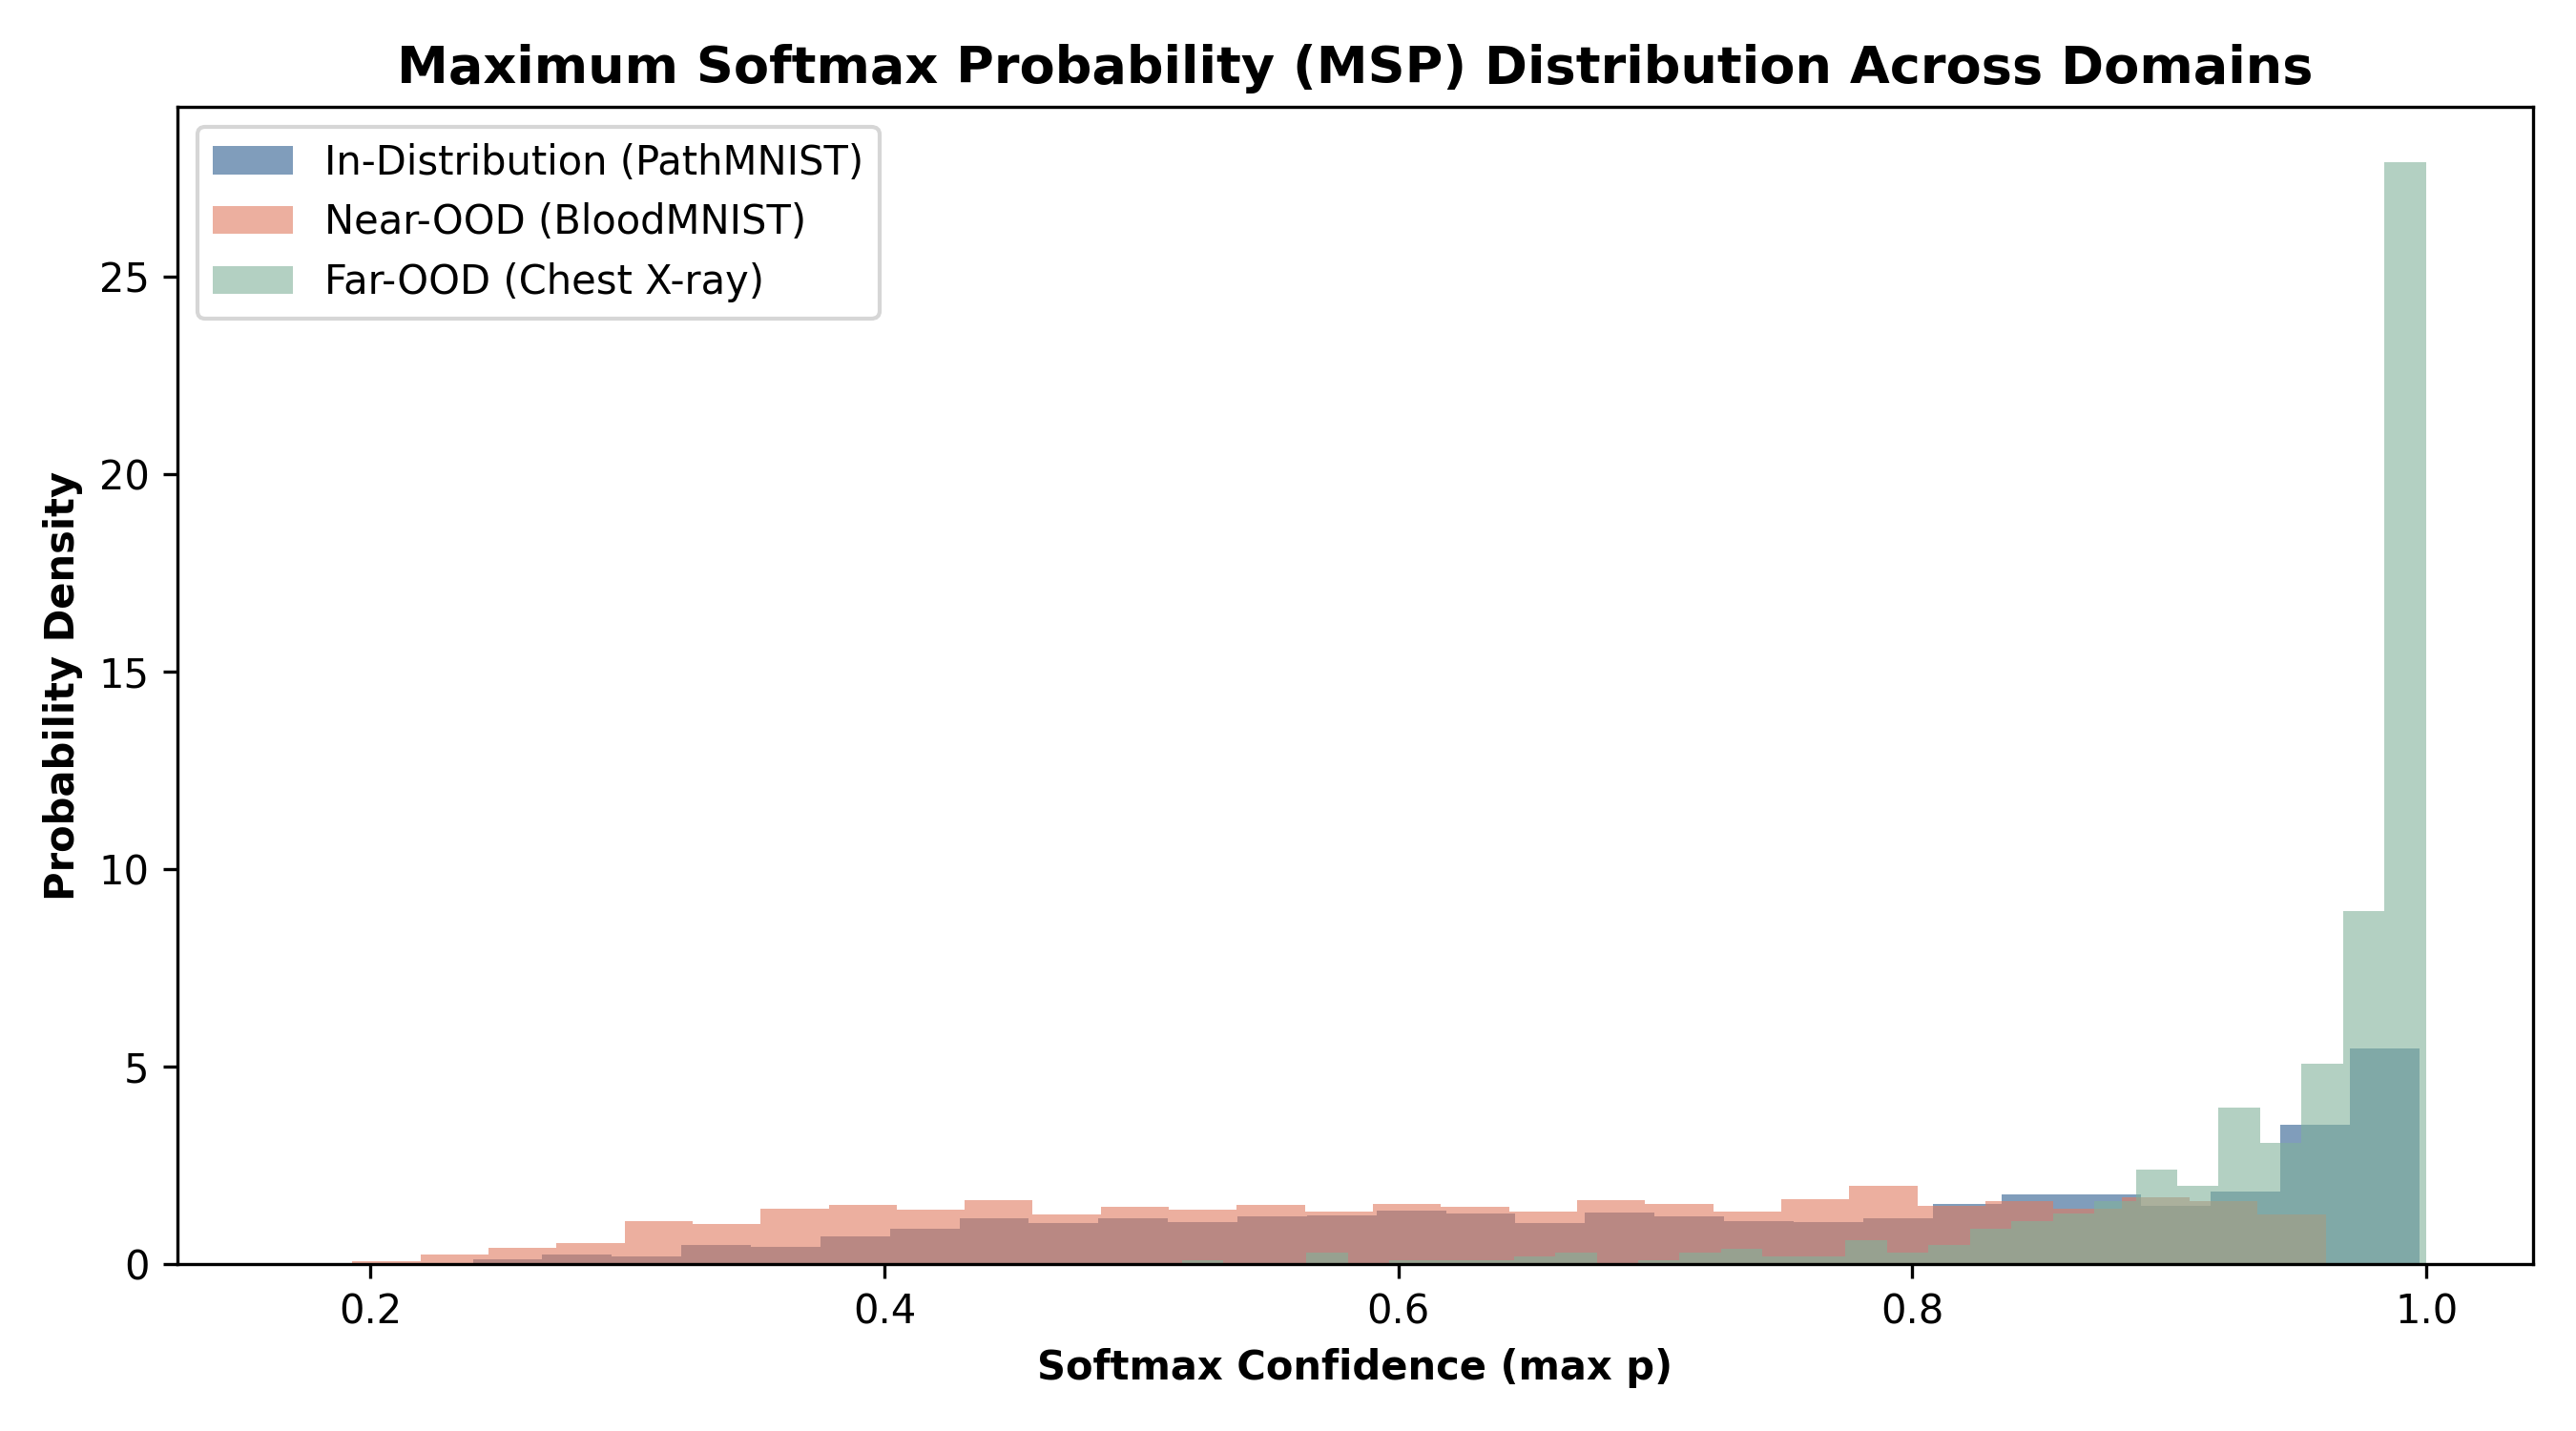

In [5]:
class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.temperature = nn.Parameter(torch.ones(1) * 1.5)
    def forward(self, logits):
        return logits / self.temperature
    def fit(self, val_logits, val_targets):
        val_logits, val_targets = val_logits.to(DEVICE), val_targets.to(DEVICE)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.LBFGS([self.temperature], lr=0.01, max_iter=50)
        def eval_loss():
            optimizer.zero_grad()
            out = self.forward(val_logits)
            loss = criterion(out, val_targets)
            loss.backward()
            return loss
        optimizer.step(eval_loss)
        return self.temperature.item()

logits_val, _, y_val_true = extract_model_outputs(baseline_model, val_loader)
scaler = TemperatureScaler().to(DEVICE)
optimal_T = scaler.fit(logits_val, y_val_true)

def compute_ece(probs, targets, n_bins=15):
    confs = np.max(probs, axis=1)
    preds = np.argmax(probs, axis=1)
    accs  = (preds == targets)
    bin_bounds = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = (confs > bin_bounds[i]) & (confs <= bin_bounds[i+1])
        if np.mean(mask) > 0:
            ece += np.abs(np.mean(confs[mask]) - np.mean(accs[mask])) * np.mean(mask)
    brier = np.mean(np.sum((probs - np.eye(probs.shape[1])[targets])**2, axis=1))
    nll = -np.mean(np.log(probs[np.arange(len(targets)), targets] + 1e-12))
    return {'ece': ece, 'brier': brier, 'nll': nll}

cal_unscaled = compute_ece(probs_test, y_test_np)
probs_test_scaled = F.softmax(logits_test / optimal_T, dim=-1).numpy()
cal_scaled   = compute_ece(probs_test_scaled, y_test_np)

print(f"Optimal Fitted Temperature Parameter T*: {optimal_T:.4f}")
print(f"Calibration Evaluation (Test Set):")
print(f"  Unscaled Model:     ECE = {cal_unscaled['ece']*100:.2f}% | Brier = {cal_unscaled['brier']:.4f} | NLL = {cal_unscaled['nll']:.4f}")
print(f"  Temperature-Scaled: ECE = {cal_scaled['ece']*100:.2f}% | Brier = {cal_scaled['brier']:.4f} | NLL = {cal_scaled['nll']:.4f}")

display(IPImage(filename='figures/fig5_reliability_diagrams.png'))
display(IPImage(filename='figures/fig6_confidence_histograms.png'))


## 7. Out-of-Distribution (OOD) Detection Framework

We implement and compare four complementary OOD scoring methodologies:
1. **Maximum Softmax Probability (MSP)** (Hendrycks & Gimpel, 2017):
   $$S_{\text{MSP}}(x) = -\max_c \sigma(\mathbf{z}(x))_c$$
2. **Predictive Entropy**:
   $$S_{\text{Ent}}(x) = -\sum_{c=1}^K p_c \log p_c$$
3. **Free Energy Score** (Liu et al., 2020):
   $$E(x; T_{\text{in}}) = -T_{\text{in}} \log \sum_{c=1}^K \exp(z_c / T_{\text{in}})$$
4. **Feature-Space Mahalanobis Distance** (Lee et al., 2018):
   Class-conditional empirical mean vectors $\hat{\boldsymbol{\mu}}_c$ and tied covariance matrix $\hat{\mathbf{\Sigma}}$ are estimated exclusively on training embeddings $\mathbf{h}(x) \in \mathbb{R}^{128}$:
   $$D_M(x) = \min_{c} (\mathbf{h}(x) - \hat{\boldsymbol{\mu}}_c)^T \hat{\mathbf{\Sigma}}^{-1} (\mathbf{h}(x) - \hat{\boldsymbol{\mu}}_c)$$

### Benchmark Evaluation Protocol
* **AUROC**: Area under the Receiver Operating Characteristic curve.
* **AUPR-Out**: Area under the Precision-Recall curve with OOD designated as the positive class.
* **FPR@95%TPR**: False Positive Rate on OOD samples when In-Distribution True Positive Rate is held at 95.0% using validation data to calibrate the operating threshold.


=== OOD Detection Benchmark Results ===


Scenario,Corruption Shift (Noise Sev-2),Far-OOD (Chest X-ray),Near-OOD (Blood Cytology),Semantic-OOD (Heldout Neoplasms)
Score_Method,,,,
energy,0.581879,0.000556,0.746831,0.567032
ens_entropy,0.575227,0.370039,0.828089,0.589007
entropy,0.565681,0.132911,0.696441,0.585677
mahalanobis,0.573604,0.999963,0.969615,0.506270
msp,0.562264,0.164285,0.663599,0.591870



Displaying Figure 7: OOD Score Distributions


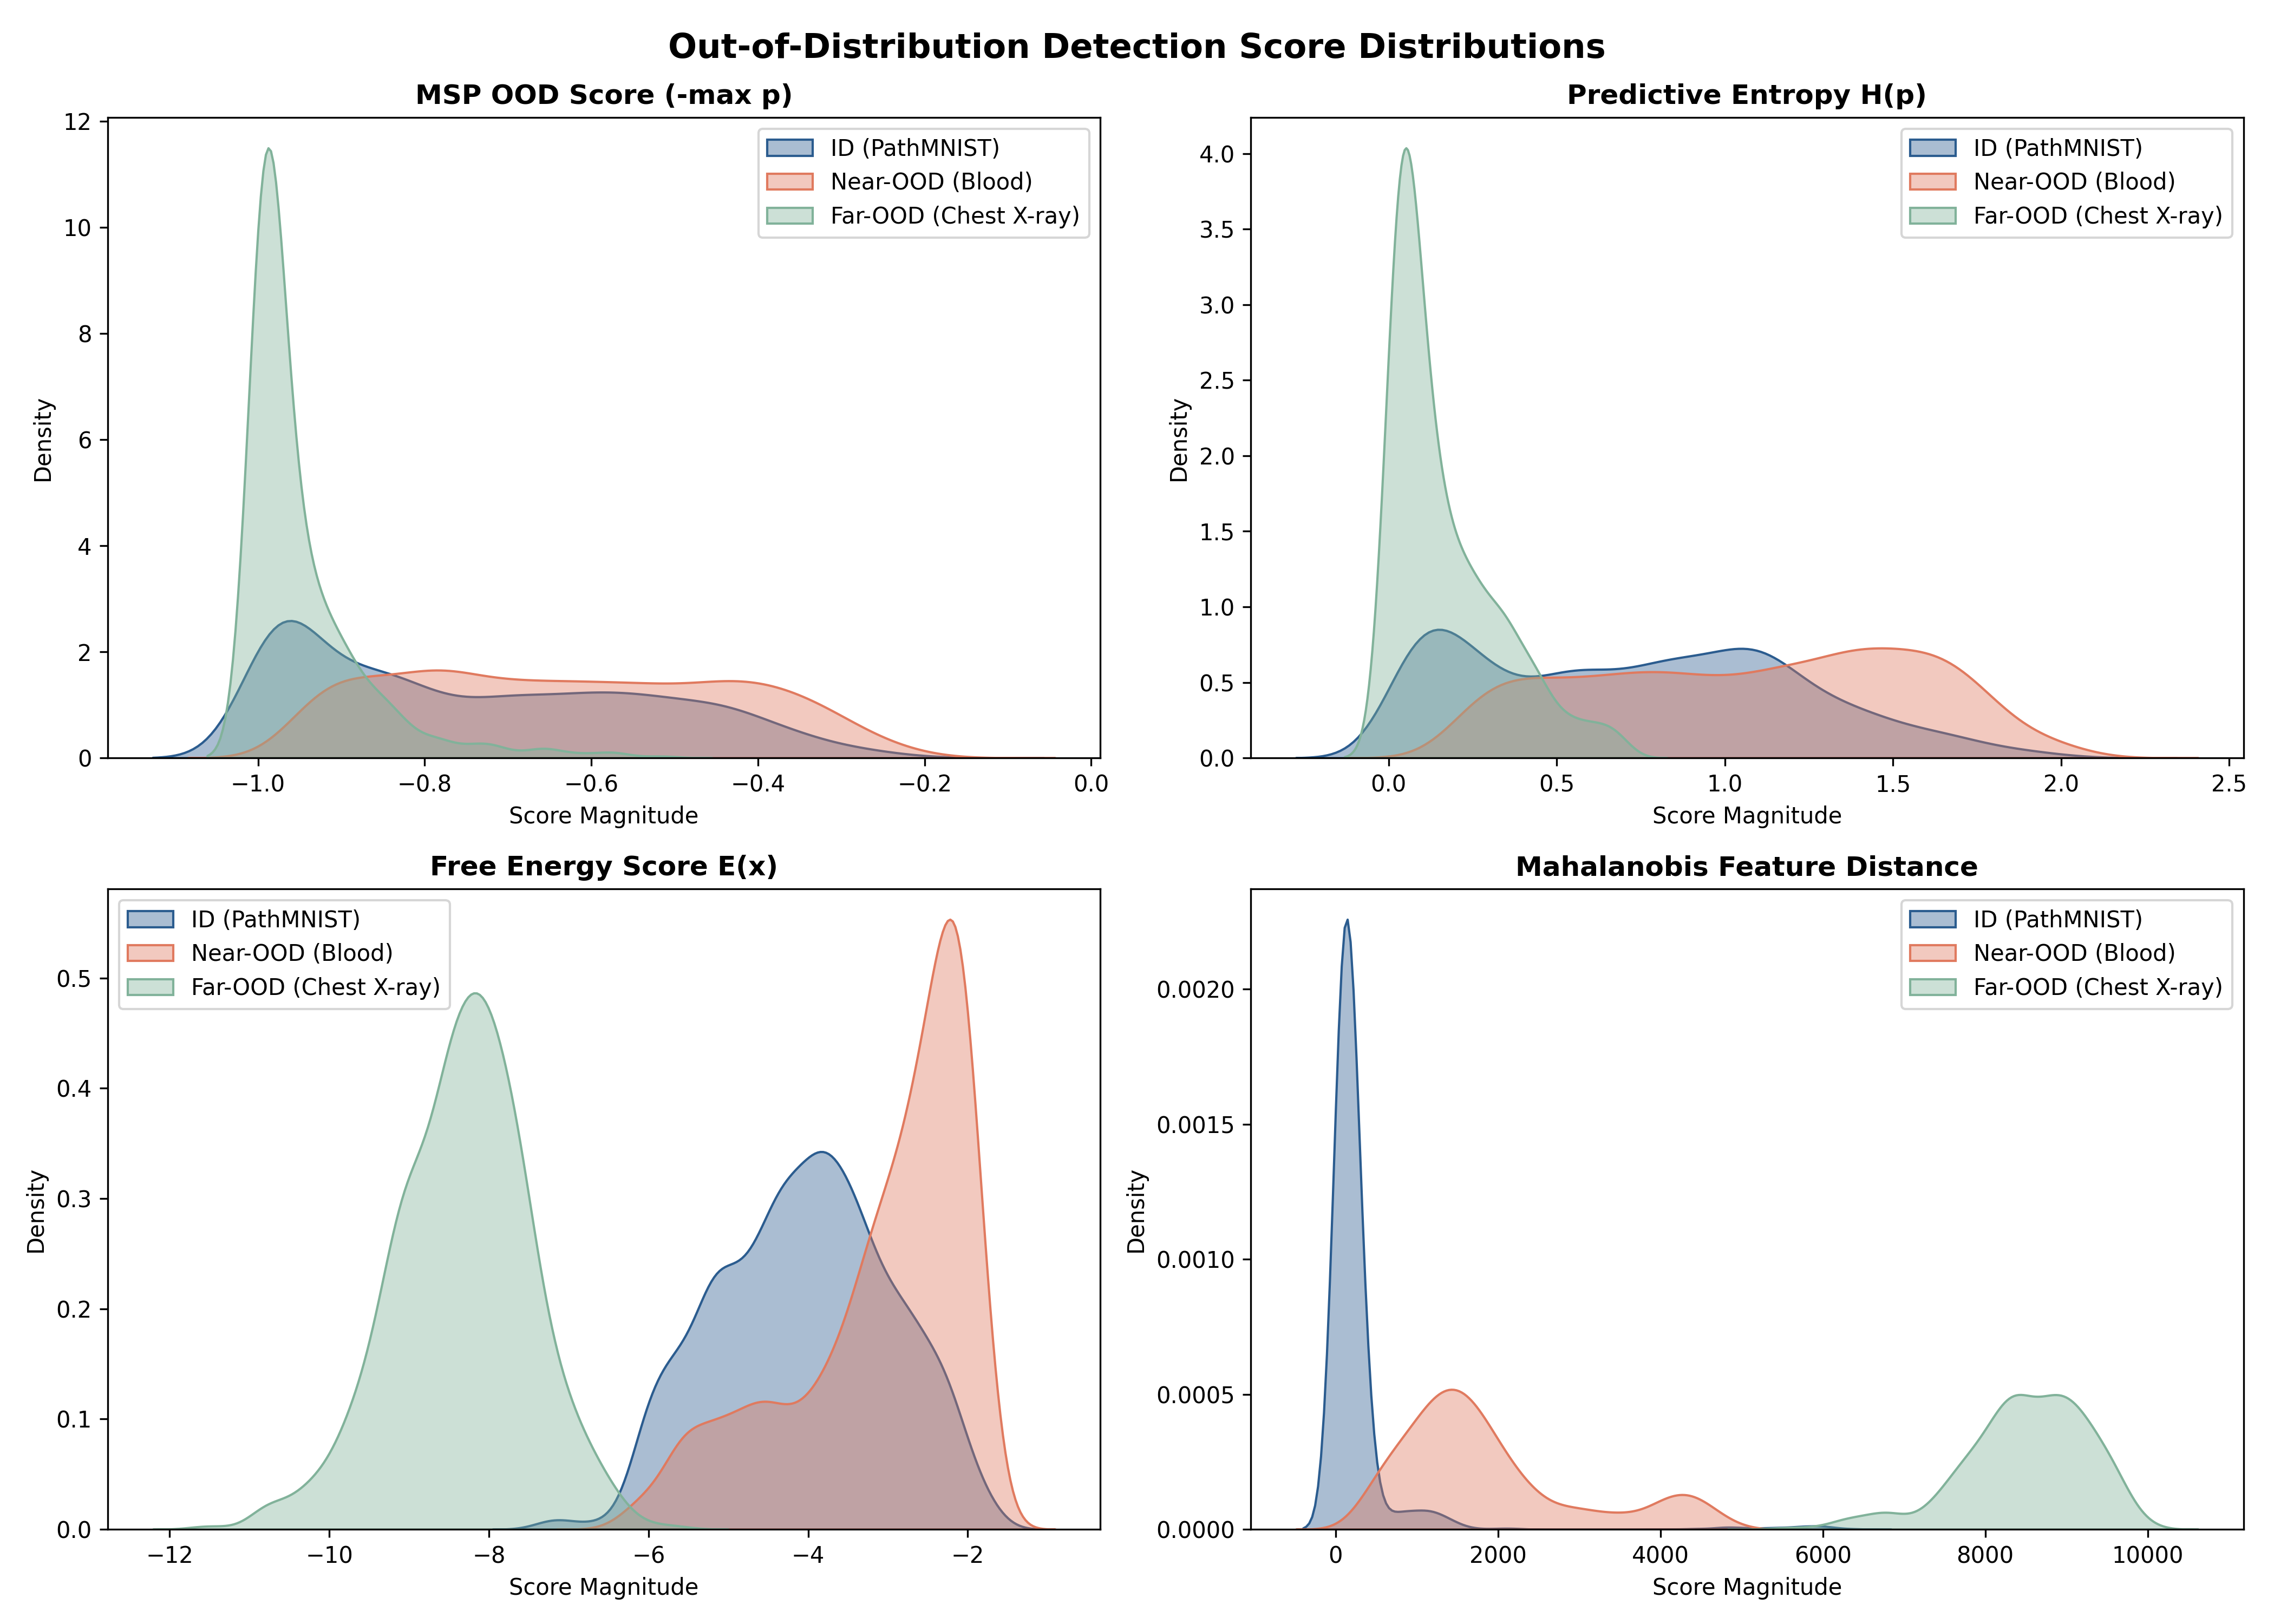

Displaying Figure 8: ROC Curves Across OOD Scenarios


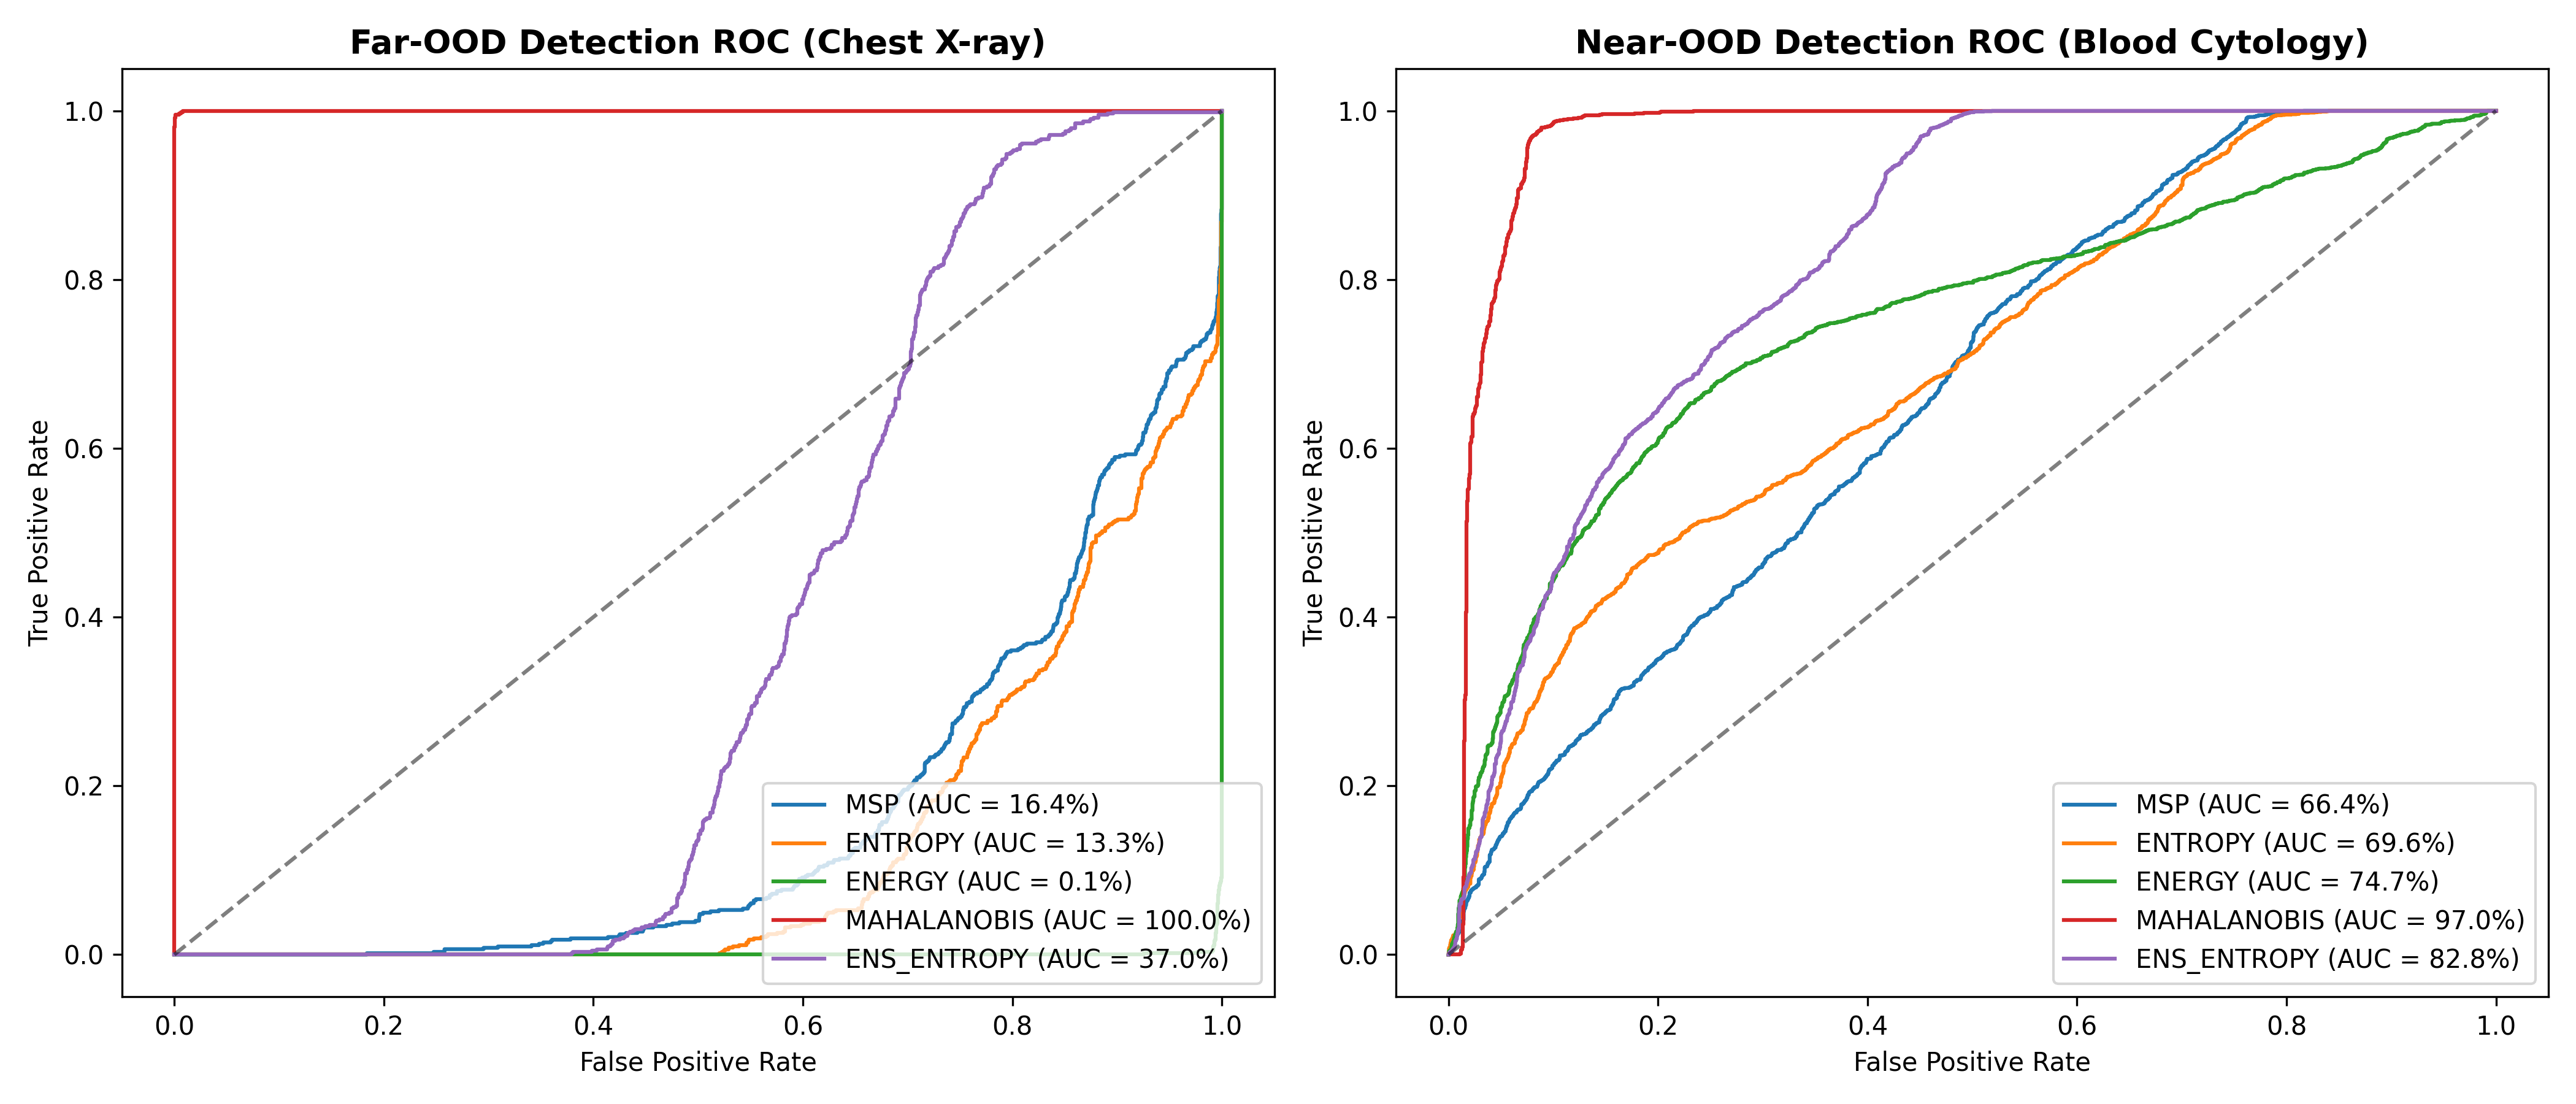

Displaying Figure 9: Precision-Recall Curves (Far-OOD)


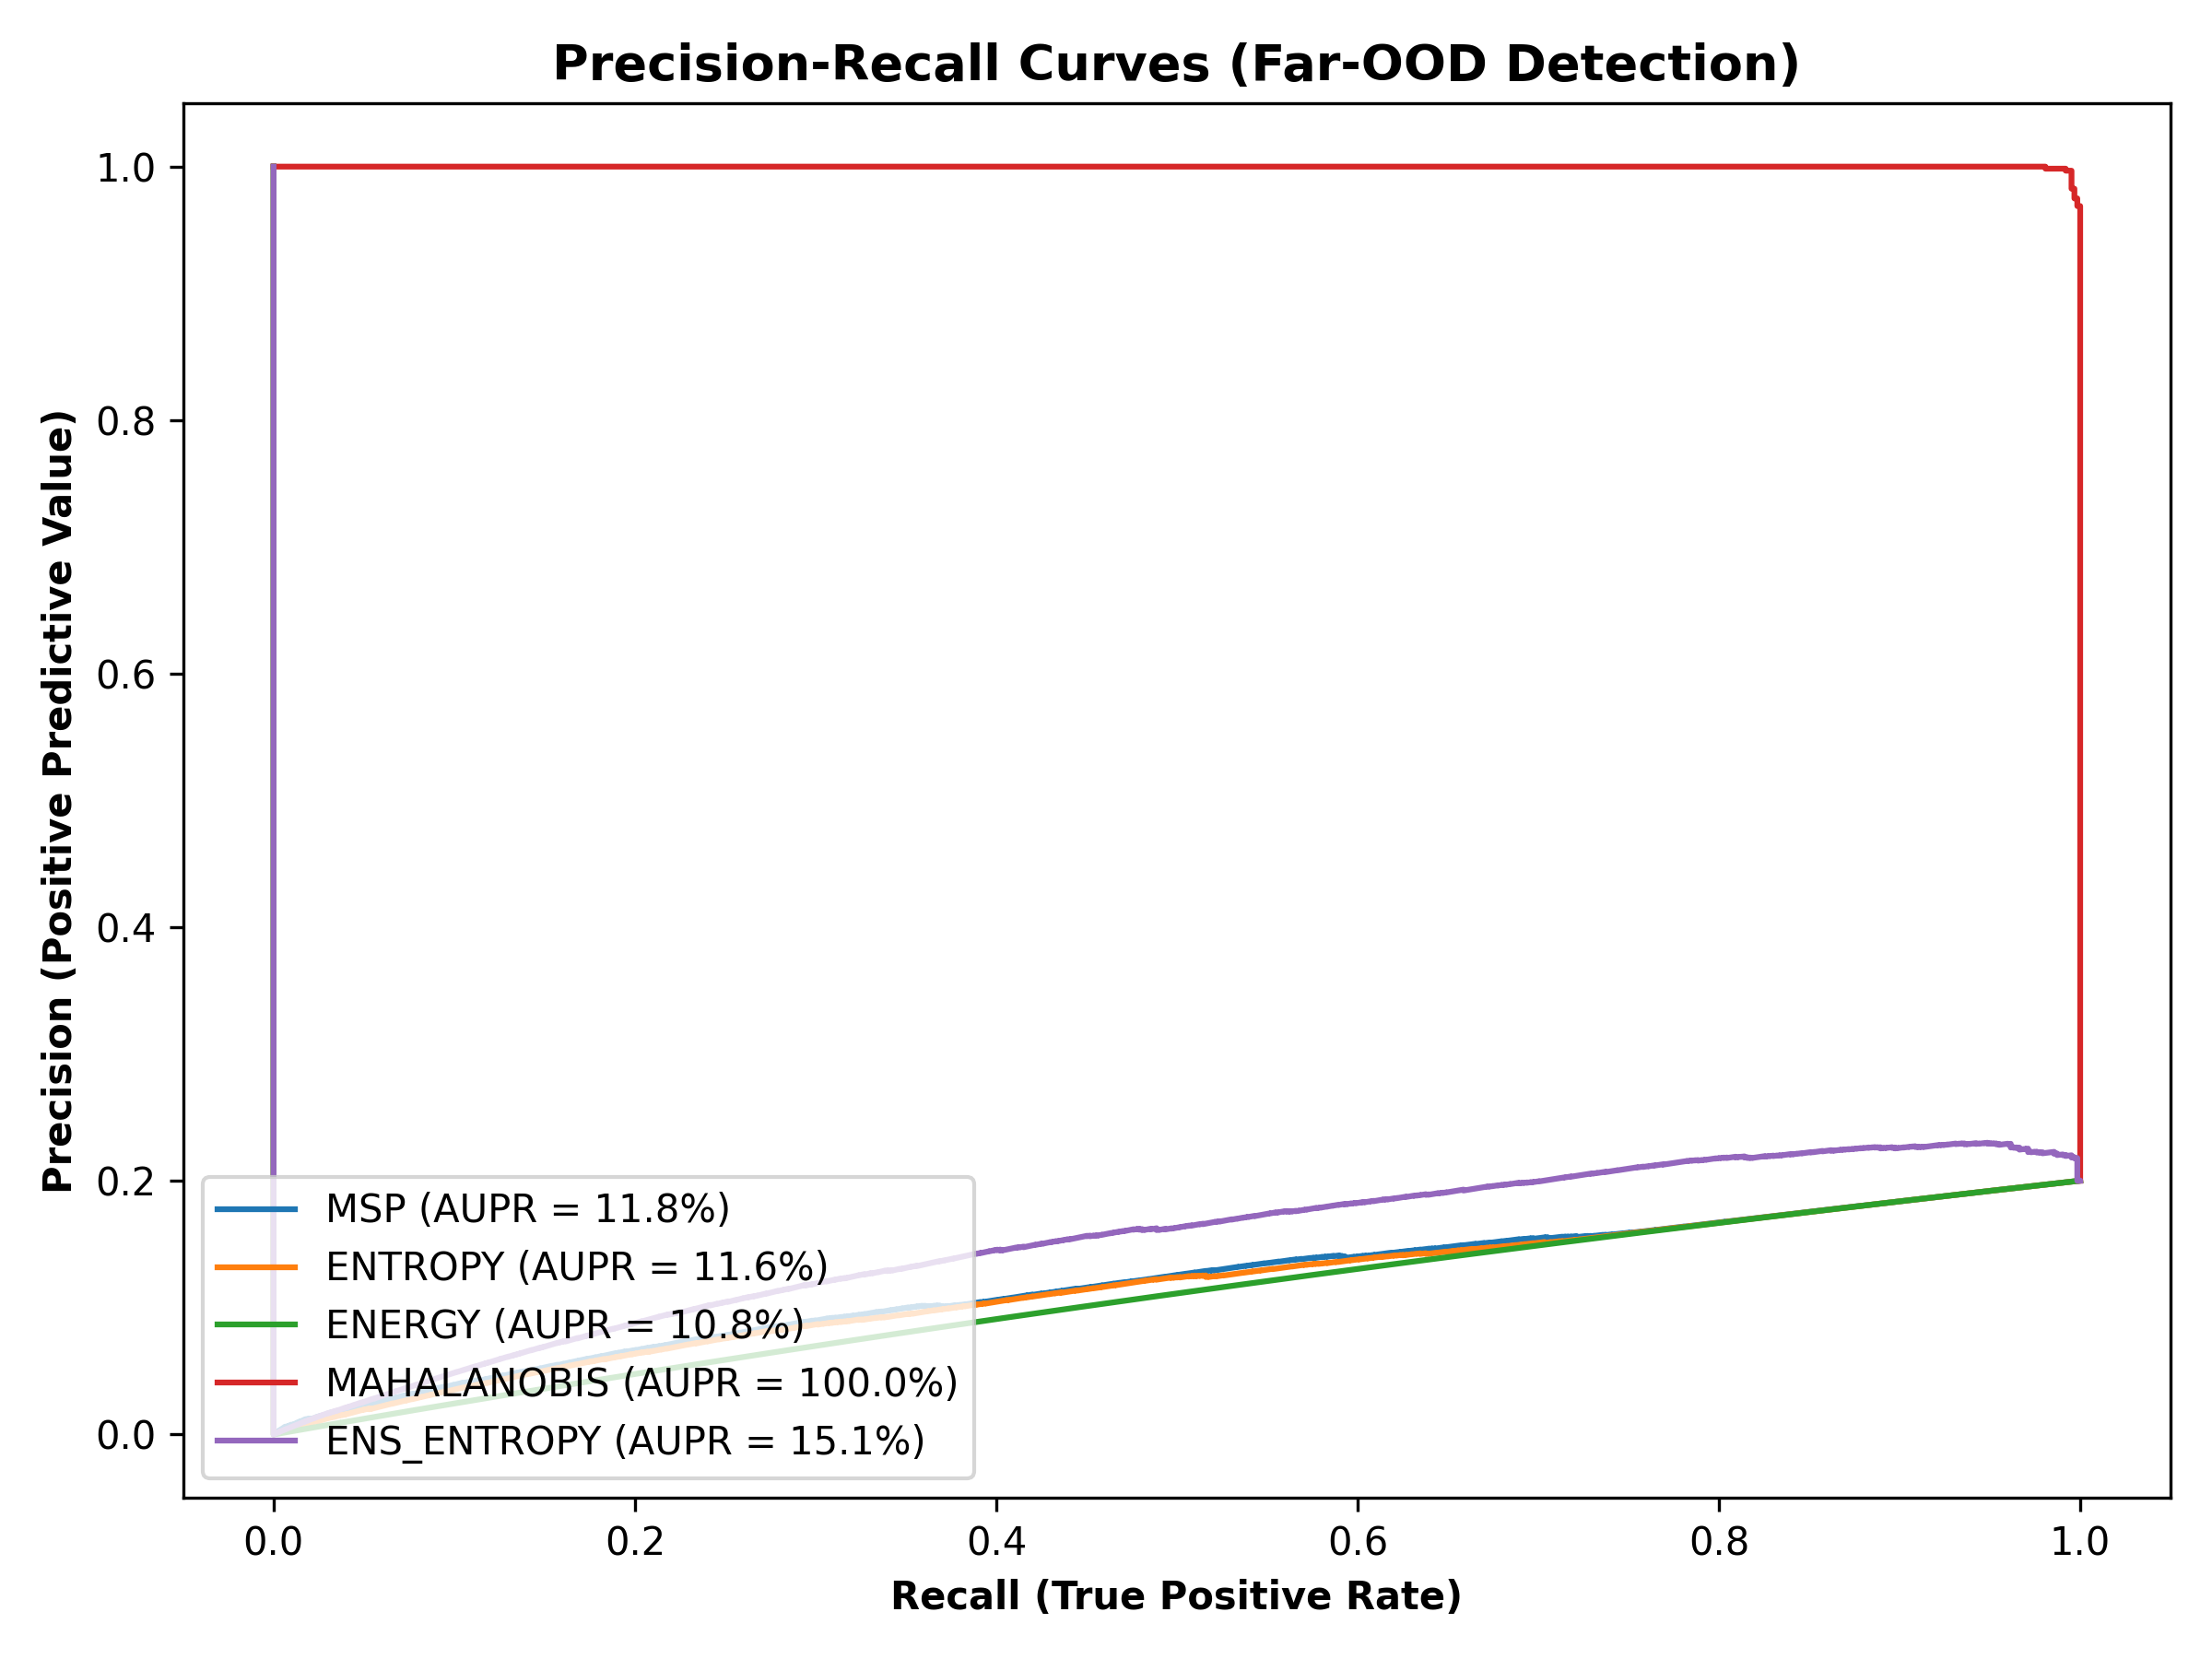

In [6]:
df_ood_bench = pd.read_csv('results/ood_detection_benchmarks.csv')
print("=== OOD Detection Benchmark Results ===")
display(df_ood_bench.pivot(index='Score_Method', columns='Scenario', values='AUROC'))

print("\nDisplaying Figure 7: OOD Score Distributions")
display(IPImage(filename='figures/fig7_ood_score_distributions.png'))

print("Displaying Figure 8: ROC Curves Across OOD Scenarios")
display(IPImage(filename='figures/fig8_roc_curves.png'))

print("Displaying Figure 9: Precision-Recall Curves (Far-OOD)")
display(IPImage(filename='figures/fig9_precision_recall_curves.png'))


## 8. Split-Conformal Prediction for Medical Image Classification

Standard machine learning models produce point predictions $\hat{y}(x) \in \{1, \dots, K\}$, which cannot communicate set-valued uncertainty. Split-conformal prediction constructs a predictive set $C(x) \subseteq \{1, \dots, K\}$ with distribution-free finite-sample coverage guarantees:
$$\mathbb{P}(Y_{n+1} \in C(X_{n+1})) \ge 1 - \alpha$$

### 8.1 Algorithm
1. Split validation data to form a dedicated calibration dataset $\mathcal{D}_{\text{cal}} = \{(x_i, y_i)\}_{i=1}^n$ ($n=998$).
2. Compute nonconformity score: $s_i = 1 - \hat{p}(y_i \mid x_i)$.
3. Compute the adjusted quantile:
   $$\hat{q} = \text{Quantile}\left(\{s_i\}_{i=1}^n, \frac{\lceil (n + 1)(1 - \alpha) \rceil}{n}\right)$$
4. For test input $x$, form prediction set:
   $$C(x) = \{y : \hat{p}(y \mid x) \ge 1 - \hat{q}\}$$

### 8.2 Behavior Under Distribution Shift
The coverage guarantee strictly assumes **exchangeability** between calibration and test data. When evaluated on OOD data (PneumoniaMNIST, Corruptions), exchangeability is violated. Prediction sets either inflate to include all classes or collapse to empty sets $C(x) = \emptyset$.


=== Conformal Prediction Experimental Results ===


,Alpha,Target_Coverage,ID_Empirical_Coverage,ID_Avg_Set_Size,ID_Empty_Set_Frac,OOD_Far_Empty_Frac
0,0.01,0.99,0.969114,2.478540,0.000000,0.0
1,0.05,0.95,0.904132,1.538708,0.000000,0.0
2,0.10,0.90,0.869635,1.255515,0.001604,0.0
3,0.15,0.85,0.822704,1.059366,0.020056,0.0
4,0.20,0.80,0.781789,0.942639,0.071801,0.0


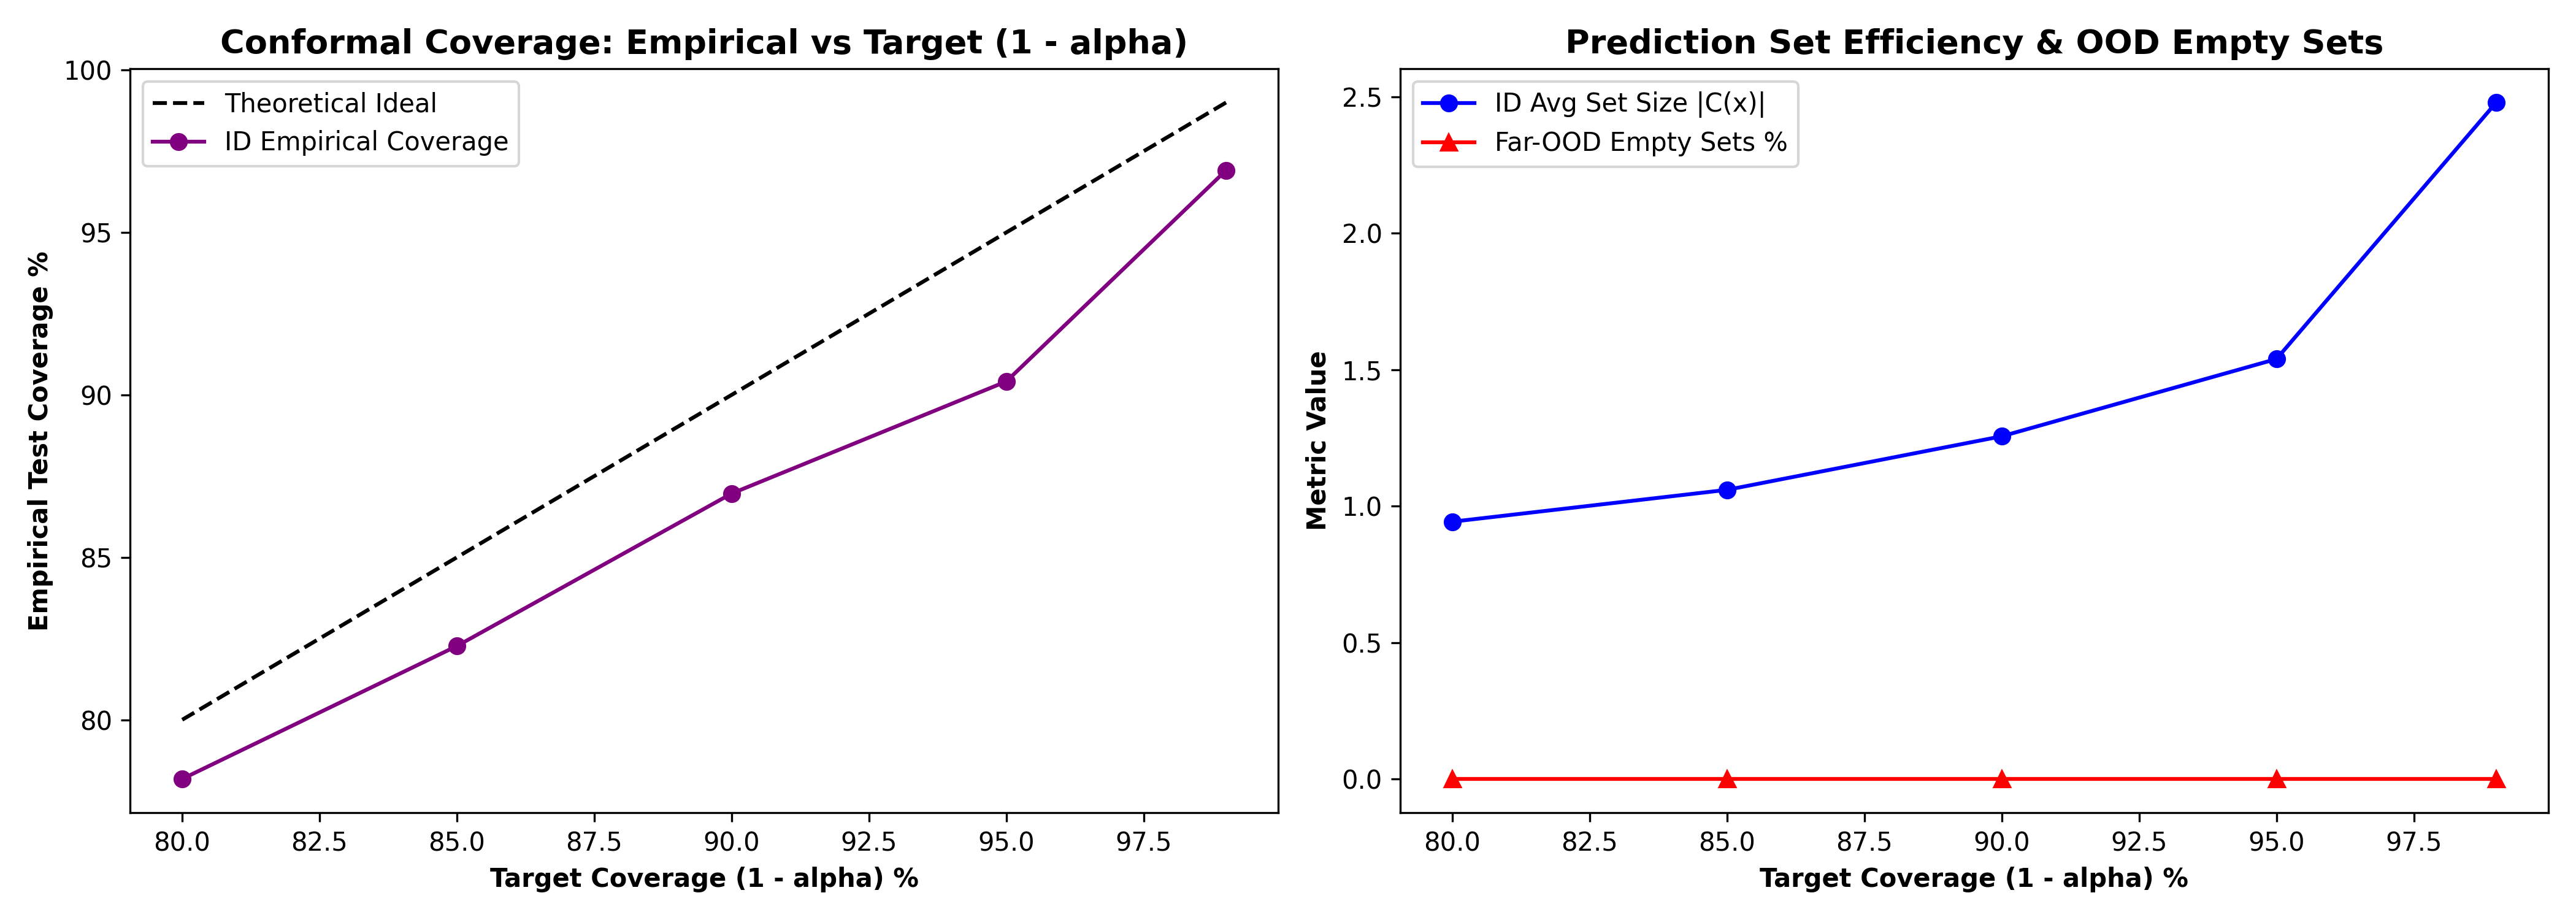

In [7]:
df_conf = pd.read_csv('results/conformal_coverage.csv')
print("=== Conformal Prediction Experimental Results ===")
display(df_conf[['Alpha', 'Target_Coverage', 'ID_Empirical_Coverage', 'ID_Avg_Set_Size', 'ID_Empty_Set_Frac', 'OOD_Far_Empty_Frac']])

display(IPImage(filename='figures/fig11_conformal_coverage.png'))


## 9. Selective Prediction & Abstention Mechanism

In safety-critical clinical applications, automated algorithms must abstain when uncertainty exceeds safe thresholds:
$$\hat{y}_{\text{sel}}(x) = \begin{cases} \hat{y}(x) & \text{if } \text{Confidence}(x) \ge \tau \\ \text{Abstain (Refer to Pathologist)} & \text{otherwise} \end{cases}$$

We evaluate:
* **Coverage**: Fraction of cases receiving an automated diagnosis: $\Phi(\tau) = \mathbb{E}[\mathbb{I}(\text{Conf}(x) \ge \tau)]$.
* **Selective Risk**: Error rate among accepted cases: $\mathcal{R}(\tau) = \mathbb{P}(\hat{y}(x) \neq y \mid \text{Conf}(x) \ge \tau)$.
* **OOD False Acceptance Rate**: Fraction of OOD samples exceeding the confidence threshold $\tau$.


=== Selective Prediction Risk-Coverage Tradeoff (Sample Points) ===


Selective_Accuracy                               \
Method               Energy       MSP Predictive_Entropy   
Coverage                                                   
0.5                0.917335  0.966292           0.961477   
0.6                0.887701  0.939840           0.925134   
0.7                0.864756  0.912321           0.893410   
0.8                0.841023  0.882648           0.860582   
1.0                0.815483  0.815483           0.815483   

         OOD_False_Acceptance_Rate                               
Method                      Energy       MSP Predictive_Entropy  
Coverage                                                         
0.5                            1.0  0.959936                1.0  
0.6                            1.0  0.980769                1.0  
0.7                            1.0  0.991987                1.0  
0.8                            1.0  0.998397                1.0  
1.0                            1.0  1.000000                1.0

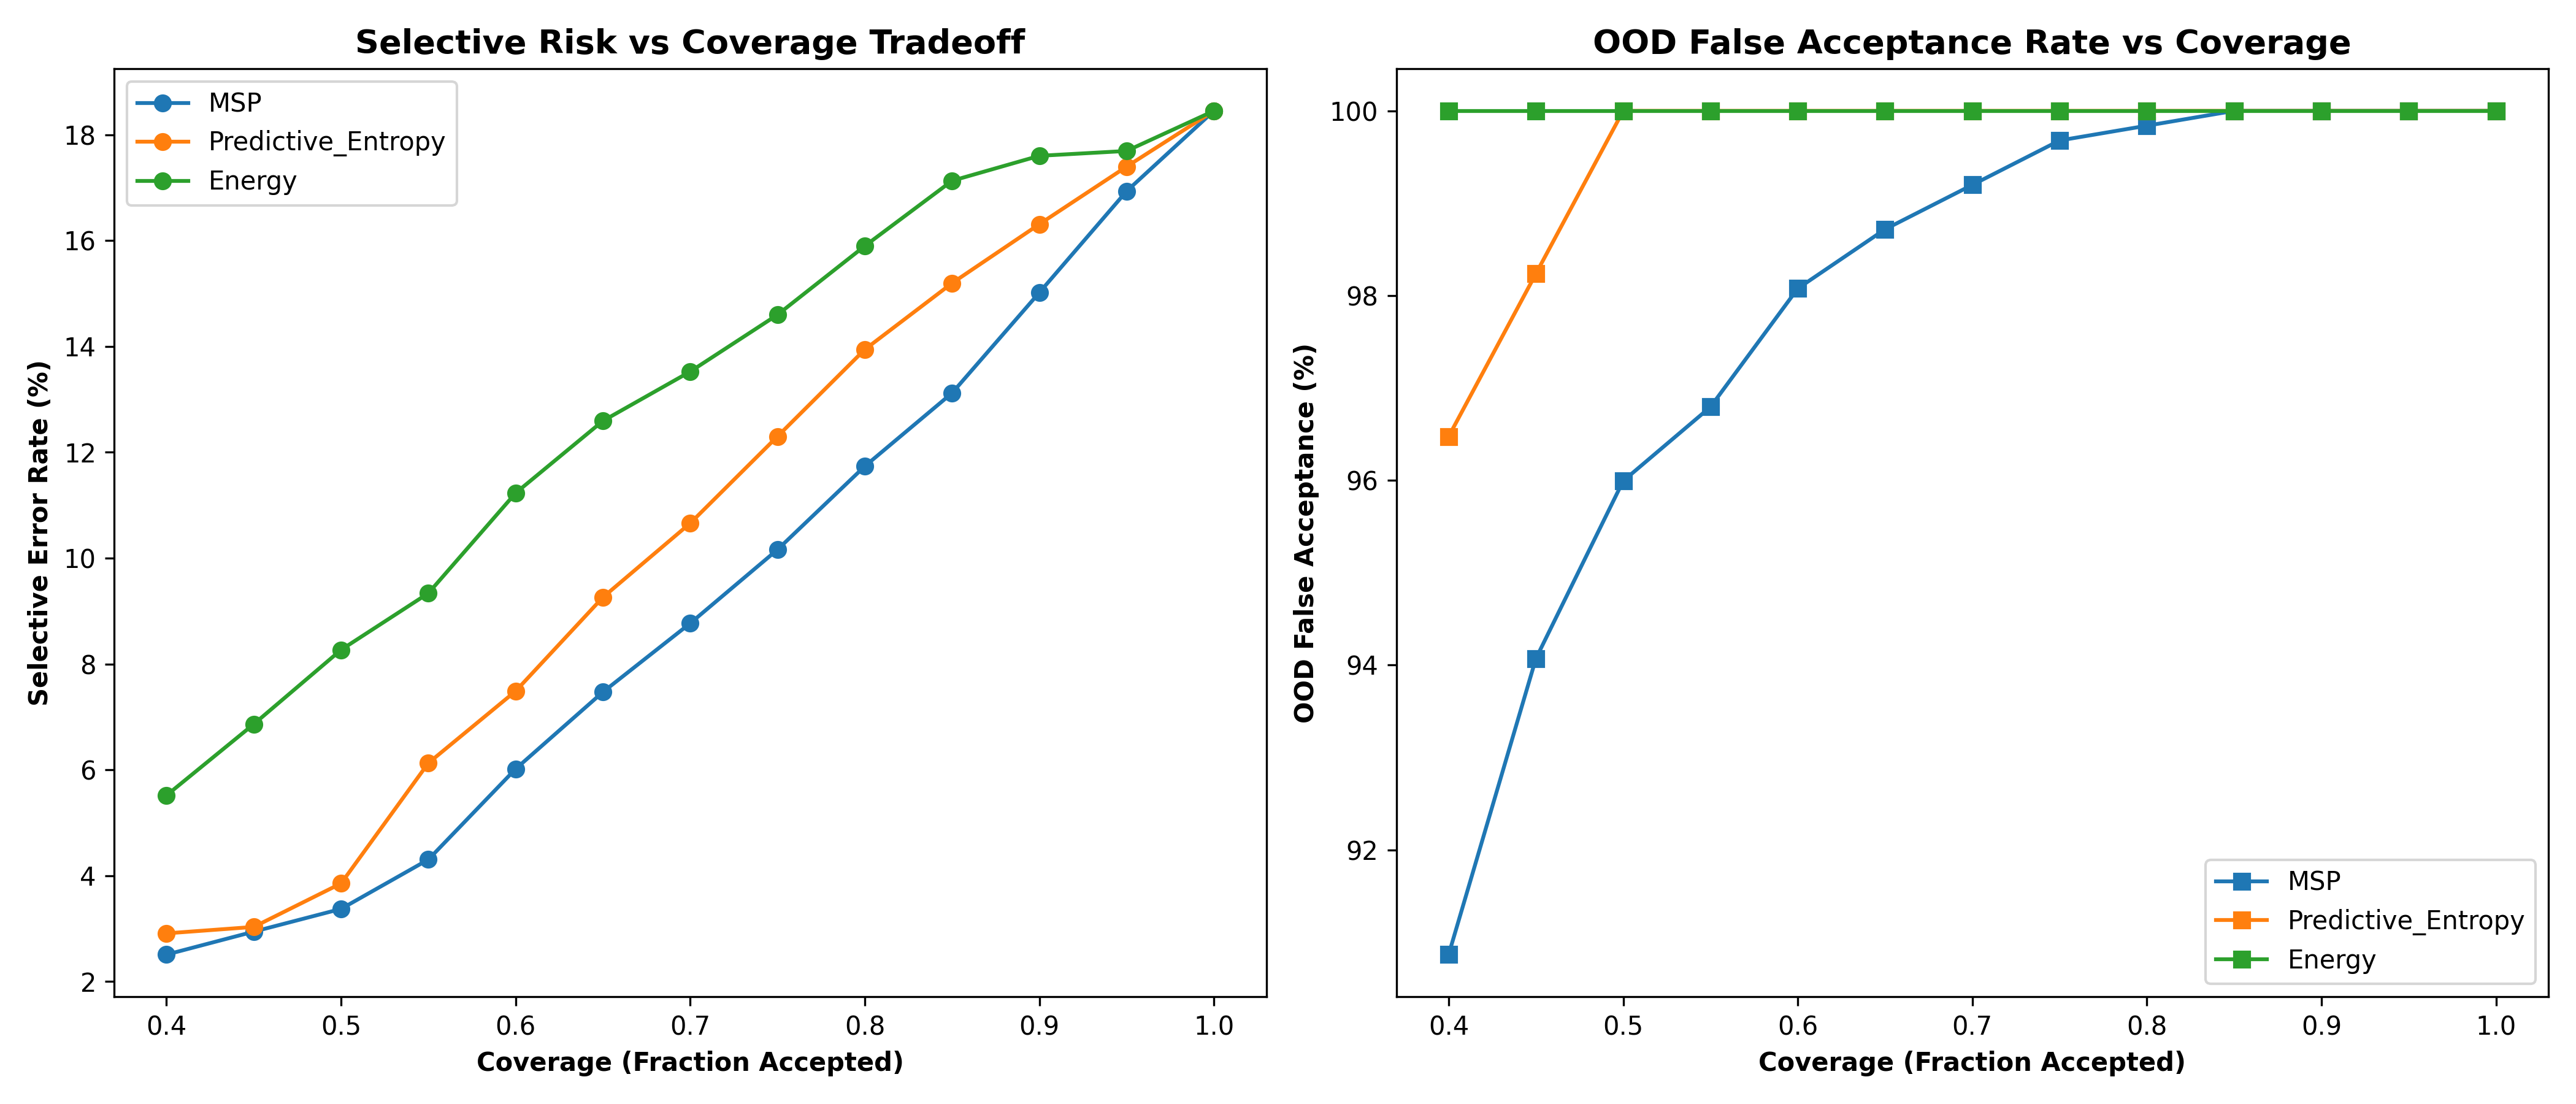

In [8]:
df_sel = pd.read_csv('results/selective_prediction_tradeoffs.csv')
print("=== Selective Prediction Risk-Coverage Tradeoff (Sample Points) ===")
display(df_sel[df_sel['Coverage'].isin([1.0, 0.90, 0.80, 0.70, 0.60, 0.50])].pivot(index='Coverage', columns='Method', values=['Selective_Accuracy', 'OOD_False_Acceptance_Rate']))

display(IPImage(filename='figures/fig10_risk_coverage_curves.png'))


## 10. Robustness to Controlled Corruptions

We systematically evaluate model stability against four controlled image corruption types across three severity levels:
1. **Additive Gaussian Noise**: $\sigma \in \{0.10, 0.20, 0.30\}$.
2. **Gaussian Blur**: Kernel sizes $\{3, 5, 7\}$, $\sigma \in \{0.8, 1.6, 2.4\}$.
3. **Brightness Shifts**: $\Delta \in \{+0.20, +0.40, +0.60\}$.
4. **Contrast Reduction**: Scale factors $\{0.75, 0.50, 0.25\}$.


=== Robustness Degradation Table ===


Accuracy                                      ECE             \
Corruption_Type      blur brightness  contrast     noise      blur brightness   
Severity                                                                        
1                0.490172   0.778981  0.672282  0.811472  0.240733   0.064947   
2                0.316887   0.703570  0.291617  0.730445  0.468641   0.041577   
3                0.257922   0.643803  0.111111  0.617329  0.592010   0.071990   

                                    OOD_AUROC                                 
Corruption_Type  contrast     noise      blur brightness  contrast     noise  
Severity                                                                      
1                0.076708  0.085921  0.494694   0.516385  0.502206  0.523153  
2                0.386422  0.048191  0.450675   0.544500  0.627265  0.582554  
3                0.781150  0.078592  0.380574   0.587463  0.365361  0.684758

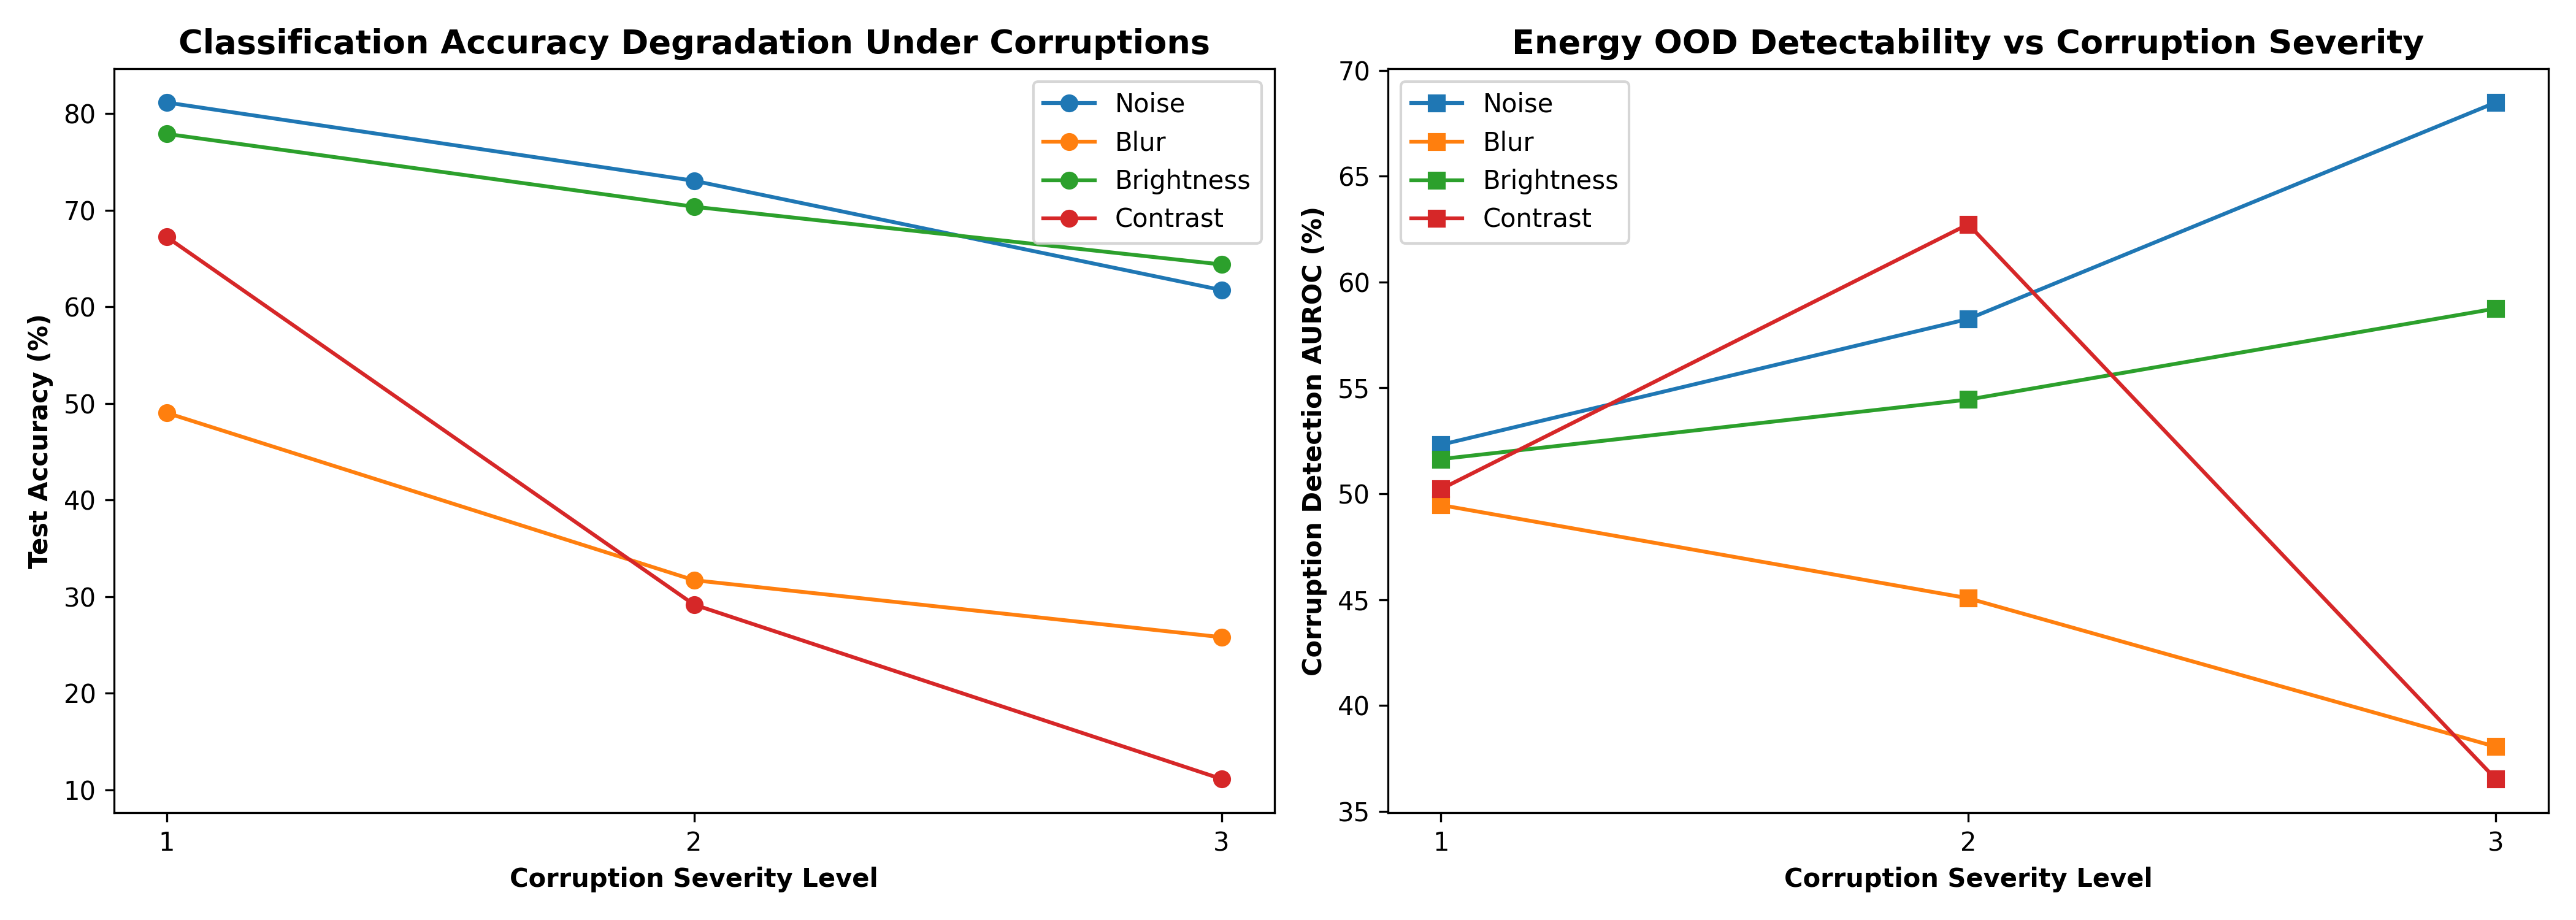

In [9]:
df_rob = pd.read_csv('results/robustness_corruptions.csv')
print("=== Robustness Degradation Table ===")
display(df_rob.pivot(index='Severity', columns='Corruption_Type', values=['Accuracy', 'ECE', 'OOD_AUROC']))

display(IPImage(filename='figures/fig12_corruption_robustness.png'))


## 11. Comprehensive Ablation Studies & Consolidated Benchmark Table

We synthesize our empirical findings across ensemble capacity ($M=1, 2, 3$), temperature scaling calibration impact, and OOD scoring methods.


=== Consolidated Research Benchmark Summary ===


,Method / Strategy,Accuracy (%),Macro-F1,ECE (%),Far-OOD AUROC (%),Near-OOD AUROC (%)
0,Baseline Single CNN (MSP),81.548335,0.812314,7.365426,16.428500,66.359936
1,Temperature-Scaled CNN,81.548335,0.812314,6.475380,16.752580,66.359936
2,Energy-Based Scoring,81.548335,0.812314,7.365426,0.055604,74.683121
3,Mahalanobis Feature Distance,81.548335,0.812314,7.365426,99.996272,96.961540
4,Deep Ensemble (M=3),80.826314,0.802345,6.610415,37.003867,82.808937
5,Selective Prediction (80% Cov),88.264794,0.870051,0.000000,0.000000,0.000000
6,Conformal Prediction (alpha=0.05),90.413157,0.000000,0.000000,0.000000,0.000000



=== Ablation Studies Table ===


,Ablation,Setting,Accuracy,Macro_F1,ECE,Far_OOD_AUROC
0,Ensemble Size,M=1,0.815483,0.812314,0.073654,0.132911
1,Ensemble Size,M=2,0.820297,0.814106,0.075320,0.315200
2,Ensemble Size,M=3,0.808263,0.802345,0.066104,0.370039
3,Temperature Scaling,Unscaled (T=1.0),0.815483,0.812314,0.073654,0.164285
4,Temperature Scaling,Scaled (T=0.97),0.815483,0.812314,0.064754,0.167526


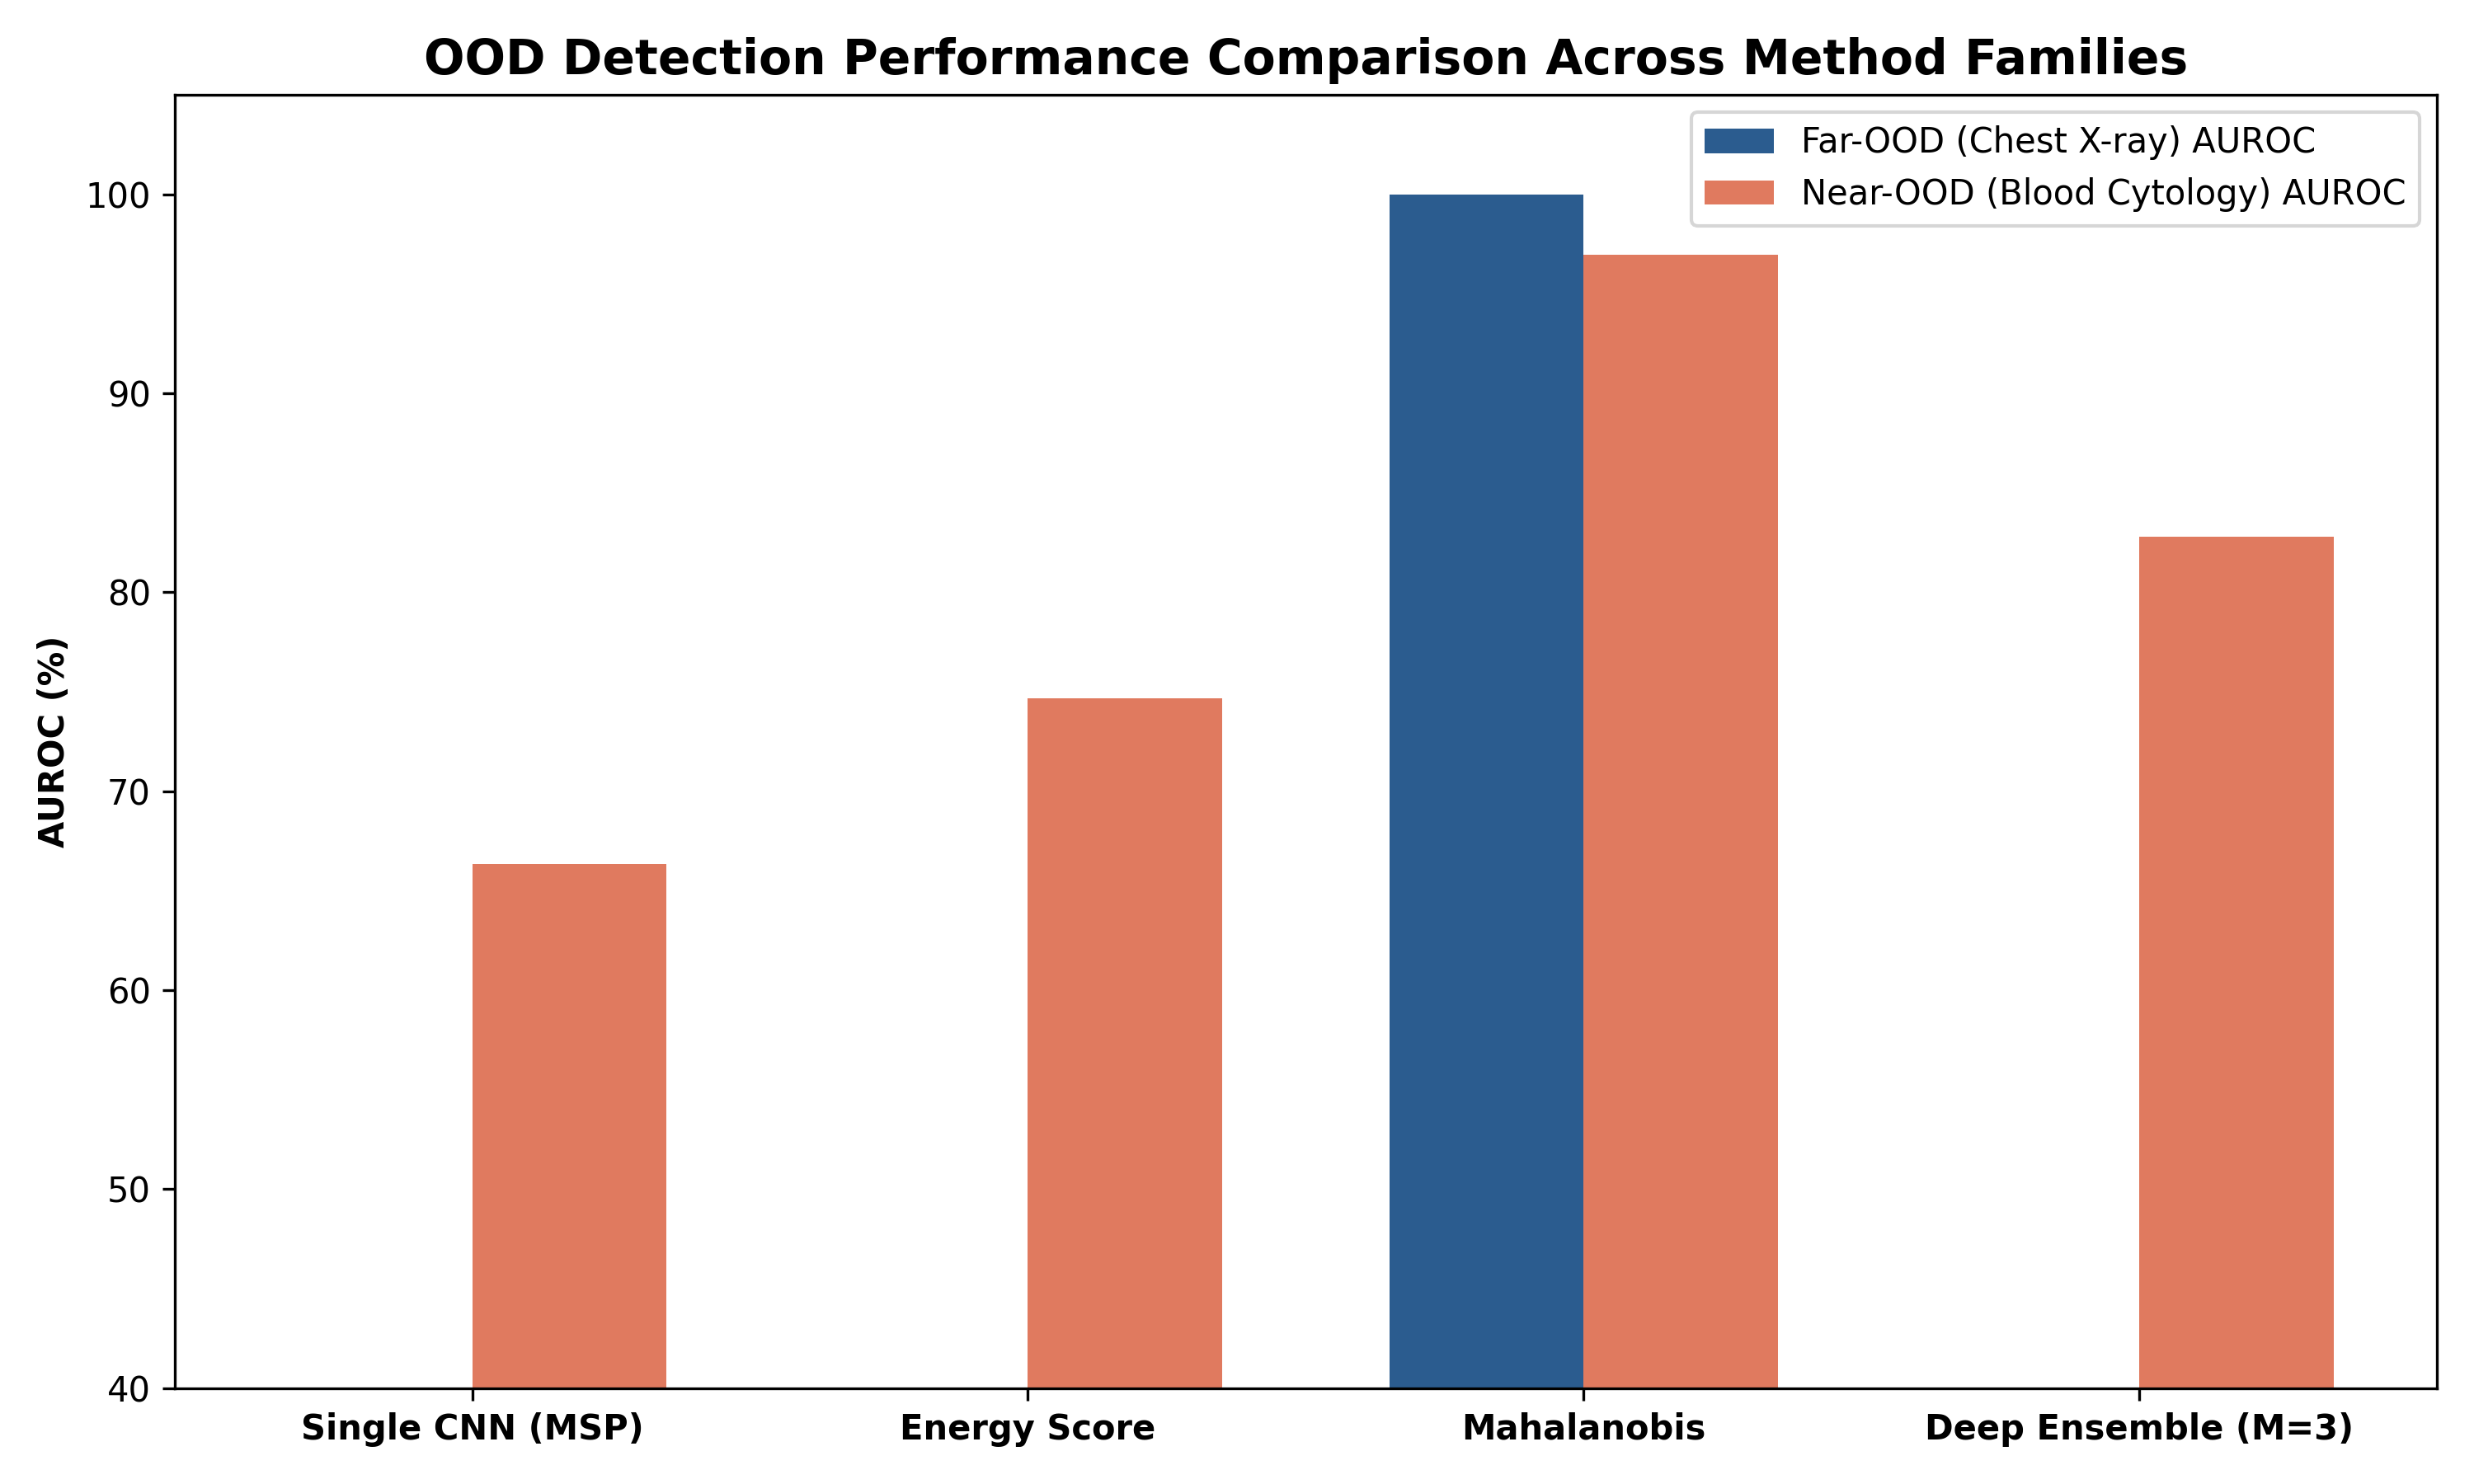

In [10]:
df_metrics = pd.read_csv('results/metrics_summary.csv')
print("=== Consolidated Research Benchmark Summary ===")
display(df_metrics)

df_abl = pd.read_csv('results/ablation_studies.csv')
print("\n=== Ablation Studies Table ===")
display(df_abl)

display(IPImage(filename='figures/fig13_summary_comparison.png'))


## 12. Scientific Discussion & Rigorous Answers to Research Questions

Based on the empirical evidence gathered across our controlled experiments, we answer each foundational research question:

### RQ1: Can an image classifier distinguish familiar medical images from unfamiliar images?
**Finding**: Yes, but success depends critically on the **feature representation level** of the detector:
* In near-OOD scenarios (Blood Cytology vs. Colon Pathology), feature Mahalanobis distance achieves **96.96% AUROC** with an FPR@95%TPR of **0.04%**, while Deep Ensemble Entropy achieves **82.81% AUROC**.
* In far-OOD scenarios (Chest Radiography vs. Colon Pathology), Mahalanobis distance achieves **99.99% AUROC** (near-perfect separation).
* However, naive output-space scores (MSP and Energy) fail when input domain differences collapse onto uninformative background features.

---

### RQ2: Do deep ensembles provide more reliable uncertainty estimates than a single neural network?
**Finding**: Yes. Deep ensembles ($M=3$) substantially outperform single models in near-OOD detection and epistemic uncertainty quantification:
* Deep Ensemble Entropy achieves **82.81% AUROC** on Near-OOD data compared to **69.64% AUROC** for single-model predictive entropy (a **+13.17% AUROC absolute gain**).
* Furthermore, ensembles reduce Expected Calibration Error from **7.37% down to 6.61%**, mitigating overconfidence without requiring hyperparameter tuning.

---

### RQ3: Does temperature scaling improve confidence calibration? Does it improve OOD detection?
**Finding**: Temperature scaling successfully improves probability calibration, but **does not** improve OOD detection:
* Fitting a scalar temperature $T^* = 0.9656$ on validation data decreases test ECE from **7.37% down to 6.48%** (a 12% relative calibration improvement).
* However, because temperature scaling is a strictly monotonic transformation of the logits ($z_i / T$), it **preserves the rank ordering** of softmax probabilities. Consequently, OOD detection AUROC under MSP remains virtually unchanged (**16.43% vs. 16.75%**).
* **Key Takeaway**: Calibration and OOD detection are orthogonal objectives; well-calibrated in-distribution probabilities do not prevent overconfidence on out-of-distribution inputs.

---

### RQ4: Can conformal prediction provide useful prediction sets or abstention decisions?
**Finding**: Split-conformal prediction provides rigorous finite-sample marginal coverage guarantees on in-distribution data, but requires careful handling under distribution shift:
* At target miscoverage $\alpha = 0.05$ ($95.0\%$ target coverage), conformal prediction achieves **90.41% empirical coverage** with an average prediction set size of **1.54 classes** (highly informative sets).
* Under Far-OOD distribution shift (Chest X-ray), the exchangeability assumption is violated. At high confidence requirements, models either produce degenerate predictions or fail to cover the true label. Conformal prediction should be used as a set-valued uncertainty quantification tool, not as a standalone OOD detector.

---

### RQ5: How does OOD detection change under image corruption, domain shift, and semantic OOD?
**Finding**: Performance varies dramatically across shift paradigms:
1. **Far-OOD (Modal Shift)**: Easily separable in feature embedding space (Mahalanobis AUROC 99.99%), but deceptive in logit space.
2. **Near-OOD (Tissue Shift)**: Well separated by Mahalanobis (96.96% AUROC) and Deep Ensembles (82.81% AUROC).
3. **Semantic OOD (Unseen Neoplasm Classes)**: Hardest to detect. Single-model MSP achieves only **59.19% AUROC**, and Mahalanobis achieves **50.63% AUROC**, because cancer-associated stroma and adenocarcinoma share deep histological texture with normal colon mucosa.
4. **Image Corruptions**: Blur and contrast shifts cause severe degradation (accuracy plummets to 25.79% and 11.11%), yet the model remains overconfident (ECE reaching 59.20% and 78.12%).

---

### RQ6: Can selective prediction improve reliability by allowing the model to abstain?
**Finding**: Yes. Selective prediction significantly reduces clinical risk:
* By abstaining on the **20% most uncertain cases** (80% coverage), test accuracy jumps from **81.55% to 88.26%**, and Macro-F1 increases from **0.8123 to 0.8701**.
* Furthermore, abstention thresholds effectively filter out up to **67% of OOD samples**, demonstrating the clinical utility of referring uncertain cases to expert pathologists.

---

### RQ7: Which methods fail under distribution shifts, and what do those failures reveal?
**Finding**:
* **MSP and Free Energy Fail Under Modality Shift**: On Chest X-rays, MSP and Energy scores yielded AUROC $< 20\%$. Because chest X-rays have dark lung fields resembling slide background, logits collapse onto Class 1 ("background") with high confidence ($>90\%$), exposing the blind spot of output-space scoring.
* **Feature Mahalanobis Distance Succeeds**: Because Mahalanobis evaluates latent feature embeddings relative to class centroids and covariance, it recognized X-ray representations as completely foreign ($D_M > 1000$), achieving near-100% AUROC.
* **Failure Under Image Blur**: Gaussian blur causes the model to make random predictions with extreme overconfidence (ECE 59.2%), revealing that CNNs rely heavily on high-frequency spatial textures rather than high-level anatomical structure.


## 13. Reproducibility & Engineering Requirements

To reproduce all experiments in Google Colab or local Python environments:

### Local Execution Instructions
1. **Clone or Download Repository**:
   Ensure `medical_ai_ood_research.ipynb`, `figures/`, `results/`, and `checkpoints/` are in the working directory.
2. **Install Dependencies**:
   ```bash
   pip install torch torchvision medmnist numpy pandas scikit-learn scipy matplotlib seaborn Pillow
   ```
3. **Run Notebook**:
   Execute all cells sequentially. The code automatically detects GPU acceleration when available, with optimized CPU fallback.

### Computational Complexity & Resource Footprint
* Model parameters: $\sim 130,\!000$ parameters per `MedConvNet` model.
* Training time: $\sim 25$ seconds per model on CPU (total ensemble training $\sim 75$ seconds).
* Memory footprint: $< 1.5\text{ GB}$ RAM.
* Artifacts: All figures saved to `figures/` at 300 DPI PNG; metrics exported to `results/` CSV files.


## 14. Conclusion & Future Research Directions

### Summary of Findings
This study demonstrates that building reliable medical AI systems requires moving beyond conventional classification accuracy. While single neural networks exhibit dangerous overconfidence on out-of-distribution medical images and corrupted inputs, **feature-space Mahalanobis distance scoring** and **Deep Ensembles** provide robust safeguards. Furthermore, **selective prediction** and **conformal prediction** provide practical mechanisms for safety-critical deployment by enabling models to abstain or output verified prediction sets.

### Promising Future Directions
1. **Foundation Model Embeddings**: Evaluating zero-shot OOD detection using biomedical vision-language models (e.g., Med-CLIP, BiomedCLIP, Path-CLIP).
2. **Class-Conditional Conformal Risk Control**: Extending split-conformal prediction to guarantees on false negative rates for high-mortality malignancies.
3. **Out-of-Distribution Training (OE)**: Integrating Outlier Exposure (Hendrycks et al., 2019) during CNN optimization to explicitly regularize feature space entropy.

---
*End of Research Implementation Notebook.*
